# 2 — Risk differentiation : modélisation (segment SB)

Ce notebook construit le modèle de scoring du segment SB (mono-détenus avec engagement), chapitre 5 du cours. Il part des **37 variables découpées et non redondantes** issues du notebook 1, avec leurs règles de découpage, et des mêmes échantillons d'apprentissage et de test.

**Démarche :**
1. **Modèle concurrent (XGBoost)** : un modèle très flexible, qui donne le niveau de performance maximal atteignable avec ces données. Il sert d'étalon.
2. **Régression logistique** : le modèle retenu pour la grille de score. Les variables sont sélectionnées pas à pas, puis le modèle est contrôlé (significativité, cohérence des coefficients, multicolinéarité) et simplifié.
3. **Comparaison** : la régression logistique est jugée par rapport à XGBoost. Un faible écart de Gini justifie de retenir le modèle interprétable.

**Mesures de performance (5.3).** Toutes les comparaisons reposent sur la capacité du modèle à **classer** les dossiers du plus risqué au moins risqué :
- **AUC** : probabilité qu'un dossier en défaut tiré au hasard ait un score plus risqué qu'un dossier sain tiré au hasard (0,5 = hasard, 1 = classement parfait) ;
- **Gini** = 2 × AUC − 1 (0 = hasard, 1 = parfait) : c'est l'indicateur principal du projet ;
- **KS** : écart maximal entre la répartition des scores des défauts et celle des sains.

## 2.1 Données et échantillons

On charge la base de modélisation exportée par le notebook 1 (variables retenues, valeurs brutes après corrections et feature engineering), les règles de découpage de chaque variable et la synthèse du binning. Les échantillons sont **exactement ceux du notebook 1** : 70 % d'apprentissage et 30 % de test, tirés par client.

In [1]:
# Cellule 1 — paramètres et chargement
from pathlib import Path
import polars as pl
from utils import binning, models
from utils.segmentation import split_train_test

pl.Config.set_tbl_rows(-1); pl.Config.set_tbl_cols(-1); pl.Config.set_tbl_width_chars(200)
pl.Config.set_tbl_hide_column_data_types(True)

ID, TARGET, DATE = "gdt", "ddefaut_ndb", "datdelhis"
CODE = "SB"
base = pl.read_parquet(f"data/processed/base_modele_{CODE}.parquet")
regles = binning.charger_regles(f"outputs/scorecard/regles_{CODE}.json")
selection = pl.read_excel(f"outputs/binning_{CODE}.xlsx", sheet_name=f"{CODE}_Selection")
VARS_MODELE = selection.filter(pl.col("statut") == "retenue")["variable"].to_list()

train, test = base.filter(pl.col("echantillon") == "train"), base.filter(pl.col("echantillon") == "test")
print(len(VARS_MODELE), "variables |", train.height, "lignes train |", test.height, "lignes test")


37 variables | 88629 lignes train | 37996 lignes test


**Échantillon de validation.** Pour choisir certains réglages (le nombre d'arbres de XGBoost, les variables de la régression), il faut mesurer la performance sur des données qui n'ont pas servi à l'estimation. Si on utilisait le test pour ces choix, il ne serait plus un juge neutre et son Gini serait trop optimiste. On met donc de côté **20 % des clients de l'apprentissage** comme échantillon de validation, avec le même tirage par client et la même stratification défaut × mois. Le test reste intouché jusqu'à la mesure finale.

| Échantillon | Rôle |
|---|---|
| estimation (80 % de l'apprentissage) | estimer les modèles |
| validation (20 % de l'apprentissage) | arrêter XGBoost, choisir les variables de la régression |
| test | mesurer la performance finale, une seule fois |

In [2]:
# Cellule 2 — échantillon de validation pour l'arrêt anticipé (20 % des clients du train)
train_v = split_train_test(train.drop("echantillon"), ID, TARGET, [DATE], part_test=0.2, seed=1)
fit = train_v.filter(pl.col("echantillon") == "train")
valid = train_v.filter(pl.col("echantillon") == "test")
print(fit.height, "lignes d'estimation |", valid.height, "lignes de validation")


70909 lignes d'estimation | 17720 lignes de validation


## 2.2 Modèle concurrent : XGBoost

XGBoost assemble des centaines de petits arbres de décision. Il capte sans contrainte les effets non linéaires et les interactions entre variables : son Gini donne donc une idée du **plafond** atteignable avec ces données. Il est estimé deux fois :
- sur les **valeurs brutes** des variables : c'est le plafond de performance ;
- sur la **WOE des classes finales** (chaque valeur remplacée par le poids de sa classe) : XGBoost dispose alors exactement de la même information que la régression logistique, ce qui mesure ce que coûte le découpage lui-même.

Pour limiter le surapprentissage avec environ 1 000 défauts, les arbres sont peu profonds (3 niveaux) et l'ajout d'arbres s'arrête dès que le Gini de validation ne progresse plus (arrêt anticipé). XGBoost reste un modèle de comparaison : il n'est pas retenu comme modèle final, car ses décisions ne se lisent pas sous forme de grille de points (exigence d'interprétabilité du scoring réglementaire).

**Que signifie « XGBoost sur la WOE » ?** Avant d'entraîner cette seconde version, chaque valeur est remplacée par la WOE de **sa classe** (découpage du notebook 1). XGBoost ne voit donc plus les valeurs exactes, seulement la classe dans laquelle tombe chaque client. Exemple avec `horsbilan`, découpée en 3 classes :

| Client | `horsbilan` | Classe | Valeur vue par XGBoost brut | Valeur vue par XGBoost WOE |
|---|---|---|---|---|
| A | 0 | ≤ 0 | 0 | −1,62 |
| B | 150 | 0 à 197,8 | 150 | −0,54 |
| C | 500 | > 197,8 | 500 | +1,32 |
| D | 15 000 | > 197,8 | 15 000 | +1,32 |

XGBoost brut distingue C et D et peut placer ses coupures où il veut ; XGBoost WOE les voit identiques, la variable n'ayant plus que 3 valeurs. Il dispose ainsi **exactement de la même information que la régression logistique**, qui ne connaît elle aussi que la classe de chaque client (à travers ses indicatrices). La WOE plutôt qu'un simple numéro de classe range en outre les classes dans l'ordre du risque, ce qui facilite les coupures des arbres ; l'information est la même.

**Pourquoi deux versions ?** Pour décomposer l'écart de performance entre la régression logistique et le meilleur modèle possible en ses deux causes :

| Comparaison | Ce qui change | Ce que mesure l'écart de Gini |
|---|---|---|
| XGBoost brut → XGBoost WOE | l'information (valeurs exactes → classes), à modèle identique | le coût du **découpage en classes** |
| XGBoost WOE → régression logistique | le modèle (flexible → additif, sans interactions), à information identique | le coût de la **forme de la régression** |

Avec un seul XGBoost, on connaîtrait l'écart total sans savoir s'il faut retravailler le découpage ou s'il s'agit de la limite inhérente à un modèle additif.

In [3]:
# Cellule 3 — XGBoost sur valeurs brutes et sur WOE, mesuré sur le train complet et le test
resultats, modeles = [], {}
for enc in ("brut", "woe"):
    X_fit, X_valid, X_train, X_test = (models.matrice_xgb(d, VARS_MODELE, regles, TARGET, enc, ref=train)
                                        for d in (fit, valid, train, test))
    m = models.entrainer_xgb(X_fit, fit[TARGET], X_valid, valid[TARGET])
    modeles[enc] = (m, X_test)
    resultats += [models.metriques(train[TARGET], m.predict_proba(X_train)[:, 1], f"XGBoost {enc} — train"),
                  models.metriques(test[TARGET], m.predict_proba(X_test)[:, 1], f"XGBoost {enc} — test")]
    print(enc, ": arrêt à", m.best_iteration + 1, "arbres")
print(pl.DataFrame(resultats).select("echantillon", "auc", "gini", "ks"))

brut : arrêt à 328 arbres
woe : arrêt à 198 arbres
shape: (4, 4)
┌──────────────────────┬──────────┬──────────┬──────────┐
│ echantillon          ┆ auc      ┆ gini     ┆ ks       │
╞══════════════════════╪══════════╪══════════╪══════════╡
│ XGBoost brut — train ┆ 0.947692 ┆ 0.895383 ┆ 0.74946  │
│ XGBoost brut — test  ┆ 0.930085 ┆ 0.86017  ┆ 0.722353 │
│ XGBoost woe — train  ┆ 0.9342   ┆ 0.868401 ┆ 0.725455 │
│ XGBoost woe — test   ┆ 0.922619 ┆ 0.845239 ┆ 0.706514 │
└──────────────────────┴──────────┴──────────┴──────────┘


**Résultats.** XGBoost atteint un **Gini test de 0,86** sur les valeurs brutes et de 0,845 sur la WOE des classes finales. L'écart entre apprentissage et test reste limité (3,5 points) : le modèle généralise bien, sans surapprentissage marqué. Le passage des valeurs brutes aux classes ne coûte que 1,5 point de Gini : le découpage du notebook 1 conserve l'essentiel de l'information. La comparaison entre XGBoost WOE et la régression logistique (section 2.4) mesurera ensuite le coût propre à la forme additive de la régression. Ces niveaux servent de référence pour juger la régression logistique.

**Importance des variables (SHAP, 10.1).** L'IV mesure le pouvoir discriminant d'une variable **prise seule**. La valeur SHAP mesure ce que chaque variable apporte réellement aux prédictions de XGBoost **en présence des autres**. Comparer les deux classements est instructif :
- une variable à **forte IV mais faible SHAP** porte une information déjà présente dans d'autres variables : elle est redondante et risque de ne rien apporter à la régression ;
- une variable à **IV modeste mais SHAP élevé** apporte une information complémentaire.

Dans le tableau, `ecart_rang` = rang IV − rang SHAP : négatif, la variable pèse moins que ne le laisse penser son IV ; positif, elle pèse plus.

In [4]:
# Cellule 4 — importance SHAP (XGBoost brut, sur le test) confrontée à l'IV
m, X_test = modeles["brut"]
shap = models.importance_shap(m, X_test, VARS_MODELE)
print(models.confronter_iv_shap(selection, shap)
)

shape: (37, 6)
┌───────────────────────────────┬──────────┬───────────┬─────────┬───────────┬────────────┐
│ variable                      ┆ iv_test  ┆ part_shap ┆ rang_iv ┆ rang_shap ┆ ecart_rang │
╞═══════════════════════════════╪══════════╪═══════════╪═════════╪═══════════╪════════════╡
│ MINSOLDE_PAR                  ┆ 1.495637 ┆ 0.111209  ┆ 5       ┆ 1         ┆ 4          │
│ CRTAE_AG_SLDEPA               ┆ 1.087963 ┆ 0.102273  ┆ 9       ┆ 2         ┆ 7          │
│ TX_UTIL_DAV                   ┆ 1.72771  ┆ 0.08043   ┆ 3       ┆ 3         ┆ 0          │
│ bilan                         ┆ 1.372296 ┆ 0.07665   ┆ 7       ┆ 4         ┆ 3          │
│ solde_crediteur               ┆ 1.73223  ┆ 0.067321  ┆ 2       ┆ 5         ┆ -3         │
│ ARR_GDT                       ┆ 1.689217 ┆ 0.066277  ┆ 4       ┆ 6         ┆ -2         │
│ horsbilan                     ┆ 1.754623 ┆ 0.062767  ┆ 1       ┆ 7         ┆ -6         │
│ anciennete_jour_sain_M0       ┆ 0.61431  ┆ 0.045755  ┆ 17      

**Résultats.** XGBoost repose surtout sur les soldes et encours (`MINSOLDE_PAR`, `CRTAE_AG_SLDEPA`, `TX_UTIL_DAV`, `bilan`, `solde_crediteur`) et sur les arriérés à date (`ARR_GDT`). Plusieurs variables à forte IV pèsent peu une fois les autres présentes : `solde_debiteur` (8e en IV, 33e en SHAP), dont l'information est reprise par le taux d'utilisation du découvert `TX_UTIL_DAV` construit à partir d'elle, `NBJ_ARR_SS` ou `ARR_TENDANCE`, redondantes avec `ARR_GDT`. À l'inverse, `SOLDE_PENTE_4T`, `RATIO_ECR` ou `anciennete_jour_sain_M0` apportent une information complémentaire malgré une IV plus modeste. Ces constats annoncent la sélection de la régression logistique.

**Optimisation des hyperparamètres.** XGBoost sert de plafond de performance : s'il est mal réglé, son Gini est sous-estimé et la comparaison favorise artificiellement la régression logistique. Ses principaux réglages (profondeur des arbres, pas d'apprentissage, taille minimale des feuilles, sous-échantillonnage, régularisation) sont donc choisis par **recherche aléatoire** : 30 combinaisons sont tirées dans une grille, et chacune est évaluée par **validation croisée par client** en 3 plis (un client n'est jamais à la fois en estimation et en validation). La combinaison retenue est celle dont le Gini moyen de validation est le plus élevé. Le test n'intervient pas.


In [5]:
# Cellule 3 bis — optimisation des hyperparamètres de XGBoost (brut), validation croisée par client sur le train
import json
X_train_brut = models.matrice_xgb(train, VARS_MODELE, regles, TARGET, "brut", ref=train)

# La recherche (30 combinaisons x 3 plis) est longue : son résultat est sauvegardé et relu aux exécutions suivantes.
# Mettre RECALCULER_XGB = True pour la relancer (par exemple si les variables ou le découpage changent).
RECALCULER_XGB = False
CHEMIN_XGB = Path(f"outputs/scorecard/params_xgb_{CODE}.json")
if CHEMIN_XGB.exists() and not RECALCULER_XGB:
    sauvegarde = json.loads(CHEMIN_XGB.read_text())
    PARAMS_XGB, essais_xgb = sauvegarde["params"], pl.DataFrame(sauvegarde["essais"])
    print("réglages relus depuis", CHEMIN_XGB)
else:
    PARAMS_XGB, essais_xgb = models.optimiser_xgb(X_train_brut, train[TARGET], train[ID], n_essais=30, n_plis=3)
    CHEMIN_XGB.write_text(json.dumps({"params": PARAMS_XGB, "essais": essais_xgb.to_dicts()}, indent=1, default=float))
print("meilleure combinaison :", PARAMS_XGB)
print(essais_xgb.head(10))

# Réestimation avec ces réglages (arrêt anticipé sur la validation), mesure sur le test
X_fit, X_valid, X_test_brut = (models.matrice_xgb(d, VARS_MODELE, regles, TARGET, "brut", ref=train) for d in (fit, valid, test))
xgb_opt = models.entrainer_xgb(X_fit, fit[TARGET], X_valid, valid[TARGET], **PARAMS_XGB)
resultats += [models.metriques(train[TARGET], xgb_opt.predict_proba(X_train_brut)[:, 1], "XGBoost optimisé — train"),
              models.metriques(test[TARGET], xgb_opt.predict_proba(X_test_brut)[:, 1], "XGBoost optimisé — test")]
print(pl.DataFrame(resultats).select("echantillon", "auc", "gini", "ks"))


réglages relus depuis outputs/scorecard/params_xgb_SB.json
meilleure combinaison : {'max_depth': 6, 'learning_rate': 0.01, 'min_child_weight': 10, 'subsample': 0.6, 'colsample_bytree': 0.7, 'reg_lambda': 10.0, 'gamma': 0.5}
shape: (10, 10)
┌───────────┬───────────────┬──────────────────┬───────────┬──────────────────┬────────────┬───────┬──────────┬────────────────────┬────────────────┐
│ max_depth ┆ learning_rate ┆ min_child_weight ┆ subsample ┆ colsample_bytree ┆ reg_lambda ┆ gamma ┆ gini_cv  ┆ gini_cv_ecart_type ┆ n_arbres_moyen │
╞═══════════╪═══════════════╪══════════════════╪═══════════╪══════════════════╪════════════╪═══════╪══════════╪════════════════════╪════════════════╡
│ 6         ┆ 0.01          ┆ 10               ┆ 0.6       ┆ 0.7              ┆ 10.0       ┆ 0.5   ┆ 0.859129 ┆ 0.00469            ┆ 762.0          │
│ 5         ┆ 0.03          ┆ 10               ┆ 0.8       ┆ 0.9              ┆ 0.1        ┆ 1.0   ┆ 0.858191 ┆ 0.005747           ┆ 140.0          │
│ 6       

**Autres modèles concurrents.** Pour vérifier que le plafond de performance ne dépend pas d'un algorithme particulier, deux autres méthodes de boosting sont entraînées dans les mêmes conditions (estimation / validation pour l'arrêt anticipé, test pour la mesure) :
- **LightGBM** : arbres construits feuille par feuille plutôt que niveau par niveau, sur les mêmes valeurs brutes que XGBoost ;
- **CatBoost** : arbres symétriques et traitement **natif** des variables qualitatives (encodage par statistiques ordonnées sur la cible, sans fuite), sans passer par la WOE.

In [6]:
# Cellule 3 ter — autres modèles concurrents : LightGBM (valeurs brutes) et CatBoost (qualitatives natives)
lgbm = models.entrainer_lgbm(X_fit, fit[TARGET], X_valid, valid[TARGET])

C_fit, CAT_IDX = models.matrice_catboost(fit, VARS_MODELE)
C_valid, C_train, C_test = (models.matrice_catboost(d, VARS_MODELE)[0] for d in (valid, train, test))
catb = models.entrainer_catboost(C_fit, fit[TARGET], C_valid, valid[TARGET], CAT_IDX)

resultats += [
    models.metriques(train[TARGET], lgbm.predict_proba(X_train_brut)[:, 1], "LightGBM — train"),
    models.metriques(test[TARGET], lgbm.predict_proba(X_test_brut)[:, 1], "LightGBM — test"),
    models.metriques(train[TARGET], catb.predict_proba(C_train)[:, 1], "CatBoost — train"),
    models.metriques(test[TARGET], catb.predict_proba(C_test)[:, 1], "CatBoost — test"),
]
print("arrêt :", lgbm.best_iteration_, "arbres (LightGBM) |", catb.get_best_iteration() + 1, "itérations (CatBoost)")
print(pl.DataFrame(resultats[-4:]).select("echantillon", "auc", "gini", "ks"))

/Users/maximethiong-ly/Desktop/GDR/Scoring/Projet-scoring/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/maximethiong-ly/Desktop/GDR/Scoring/Projet-scoring/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


arrêt : 203 arbres (LightGBM) | 530 itérations (CatBoost)
shape: (4, 4)
┌──────────────────┬──────────┬──────────┬──────────┐
│ echantillon      ┆ auc      ┆ gini     ┆ ks       │
╞══════════════════╪══════════╪══════════╪══════════╡
│ LightGBM — train ┆ 0.969623 ┆ 0.939246 ┆ 0.819584 │
│ LightGBM — test  ┆ 0.931997 ┆ 0.863995 ┆ 0.730545 │
│ CatBoost — train ┆ 0.948862 ┆ 0.897723 ┆ 0.755794 │
│ CatBoost — test  ┆ 0.927784 ┆ 0.855568 ┆ 0.722631 │
└──────────────────┴──────────┴──────────┴──────────┘


**Résultats.** Les 30 combinaisons essayées donnent des Gini de validation croisée très proches : les dix meilleures se tiennent en 0,3 point (0,856 à 0,859), soit moins que la variabilité entre plis (écart-type d'environ 0,5 point). L'optimum est plat. La meilleure combinaison (arbres de profondeur 6, pas d'apprentissage 0,01, forte régularisation) atteint un Gini test de 0,862, contre 0,860 avec les réglages par défaut : le gain est négligeable, et l'écart apprentissage / test un peu plus élevé (4,6 points contre 3,5). Les réglages par défaut étaient donc déjà proches de l'optimum, et le plafond de performance de ces données est robuste, autour de 0,86.

## 2.3 Régression logistique : sélection des variables 

**Encodage.** Chaque variable entre dans la régression sous forme d'**indicatrices** (une colonne 0/1 par classe). Une classe par variable sert de **référence** et n'a pas d'indicatrice : on prend la **moins risquée**. Le coefficient d'une classe mesure alors le supplément de risque par rapport à cette référence. Conséquence : tous les coefficients doivent être **positifs**, et **croissants** d'une classe à la plus risquée suivante. Un coefficient qui ne respecte pas cet ordre traduit un problème (multicolinéarité, classe instable) et rendrait la grille de score incohérente.

**Sélection pas à pas par ordre de liaison.** Les 37 variables sont essayées une par une, de la plus forte IV à la plus faible. À chaque essai, on ajoute la variable au modèle courant et on ne la **garde que si trois conditions sont réunies** :
1. elle est **significative** : le test du rapport de vraisemblance (modèle avec contre modèle sans la variable) est significatif à 5 % ;
2. elle **améliore le Gini de validation** d'au moins 0,2 point : une variable significative mais qui n'améliore pas le classement n'apporte rien à la grille ;
3. tous les **coefficients du modèle restent cohérents** (positifs et croissants), y compris ceux des variables déjà retenues.

Le modèle est estimé sur l'échantillon d'estimation et le gain de Gini est mesuré sur la validation : le test n'intervient pas. Le journal ci-dessous donne, pour chaque variable, la décision et son motif.

In [7]:
# Cellule 5 — sélection pas à pas par ordre de liaison
ORDRE = selection.filter(pl.col("statut") == "retenue").sort("iv_test", descending=True)["variable"].to_list()
VARS_LOGIT, journal = models.stepwise_liaison(fit, valid, ORDRE, regles, TARGET, alpha=0.05, gain_gini_min=0.002)
print(len(VARS_LOGIT), "variables retenues :", VARS_LOGIT)
print(journal)


10 variables retenues : ['horsbilan', 'solde_crediteur', 'TX_UTIL_DAV', 'ARR_GDT', 'MINSOLDE_PAR', 'CRTAE_AG_SLDEPA', 'ARR_TENDANCE', 'anciennete_jour_sain_M0', 'RATIO_ECR', 'CODITDBDF_PAR']
shape: (37, 7)
┌───────────────────────────────┬───────────┬─────────────┬────────────┬───────────┬──────────┬─────────────────────────────────┐
│ variable                      ┆ n_classes ┆ p_lr        ┆ gini_valid ┆ gain_gini ┆ decision ┆ motif                           │
╞═══════════════════════════════╪═══════════╪═════════════╪════════════╪═══════════╪══════════╪═════════════════════════════════╡
│ horsbilan                     ┆ 3         ┆ 0.0         ┆ 0.622175   ┆ 0.622175  ┆ retenue  ┆                                 │
│ solde_crediteur               ┆ 5         ┆ 1.6366e-131 ┆ 0.765612   ┆ 0.143436  ┆ retenue  ┆                                 │
│ TX_UTIL_DAV                   ┆ 4         ┆ 3.4587e-25  ┆ 0.780573   ┆ 0.014961  ┆ retenue  ┆                                 │
│ ARR_GDT     

**Résultats.** La sélection retient **10 variables sur 37** : `horsbilan`, `solde_crediteur`, `TX_UTIL_DAV`, `ARR_GDT`, `MINSOLDE_PAR`, `CRTAE_AG_SLDEPA`, `ARR_TENDANCE`, `anciennete_jour_sain_M0`, `RATIO_ECR` et `CODITDBDF_PAR`. Les variables écartées le sont :
- pour **gain de Gini insuffisant** : leur information est déjà portée par les variables retenues, comme l'annonçait l'analyse SHAP (`solde_debiteur`, `bilan`, `NBJ_ARR_SS`, `NBJ_ARR_MAX_12M`…) ;
- pour **non-significativité** une fois les autres variables présentes (`ANCIENNETE_modif`, `PART_EPARGNE_DANS_AVOIRS`…) ;
- pour **incohérence des coefficients** (`NBJ_ARR_MAX_13_48M`, `engagement`).

**L'âge** (`AGE_PP_EN_MOIS`) n'est pas significatif (p = 0,68) et n'entre pas dans le modèle : la question de la non-discrimination liée à l'âge ne se pose donc pas pour ce segment.

**Second passage.** Le stepwise juge chaque variable une seule fois, face au modèle du moment : une variable écartée tôt peut apporter de l'information une fois les autres présentes (par exemple `bilan`, essayée quand le modèle ne comptait que 5 variables). Chaque variable écartée est donc **réessayée face au modèle complet**, avec les mêmes critères (significative, gain de Gini de validation d'au moins 0,2 point, coefficients cohérents) ; à chaque tour, la meilleure entre, jusqu'à ce qu'aucune ne passe. Le journal ne montre que les variables significatives.

In [8]:
# Cellule 5 bis — second passage : les variables écartées sont réessayées face au modèle complet
ECARTEES = [v for v in ORDRE if v not in VARS_LOGIT]
VARS_LOGIT, journal_2 = models.reexaminer_ecartees(fit, valid, VARS_LOGIT, ECARTEES, regles, TARGET,
                                                   alpha=0.05, gain_gini_min=0.002)
print(len(VARS_LOGIT), "variables après le second passage :", VARS_LOGIT)
print(journal_2.filter(pl.col("p_lr") < 0.05).sort(["tour", "gain_gini"], descending=[False, True]))

10 variables après le second passage : ['horsbilan', 'solde_crediteur', 'TX_UTIL_DAV', 'ARR_GDT', 'MINSOLDE_PAR', 'CRTAE_AG_SLDEPA', 'ARR_TENDANCE', 'anciennete_jour_sain_M0', 'RATIO_ECR', 'CODITDBDF_PAR']
shape: (12, 8)
┌──────┬─────────────────────────┬────────────┬────────────┬───────────┬──────────┬──────────┬──────────┐
│ tour ┆ variable                ┆ p_lr       ┆ gini_valid ┆ gain_gini ┆ coherent ┆ eligible ┆ decision │
╞══════╪═════════════════════════╪════════════╪════════════╪═══════════╪══════════╪══════════╪══════════╡
│ 1    ┆ SOLDE_EVOLUTION_T_vs_T4 ┆ 0.008396   ┆ 0.836338   ┆ 0.001685  ┆ false    ┆ false    ┆          │
│ 1    ┆ SOLDE_VOLATILITE_5T     ┆ 0.000003   ┆ 0.835839   ┆ 0.001186  ┆ false    ┆ false    ┆          │
│ 1    ┆ NBJ_ARR_MAX_13_48M      ┆ 0.000005   ┆ 0.835576   ┆ 0.000923  ┆ false    ┆ false    ┆          │
│ 1    ┆ CAUSE_SAIN_M0           ┆ 0.000002   ┆ 0.835498   ┆ 0.000845  ┆ true     ┆ false    ┆          │
│ 1    ┆ engagement              ┆ 7.

**Résultats du second passage.** Aucune variable n'entre : le modèle reste à **10 variables**. Douze variables écartées sont significatives face au modèle complet, mais aucune ne remplit les trois critères à la fois :
- les plus prometteuses en Gini (`SOLDE_EVOLUTION_T_vs_T4` +0,17 pt, `SOLDE_VOLATILITE_5T` +0,12 pt, `NBJ_ARR_MAX_13_48M`, `engagement`, `solde_debiteur`) rendent le modèle **incohérent** (leurs coefficients ou ceux d'une variable déjà présente) ;
- celles dont les coefficients restent cohérents (`CAUSE_SAIN_M0`, `Dfo_max_Mm4_Mm36`, `NBJ_ARR_SS`, `nb_CB_diff`) apportent **moins de 0,1 point** de Gini de validation, voire en font perdre ;
- `bilan` fait perdre du Gini (−0,06 point) et rend le modèle incohérent.

La sélection du premier passage ne dépendait donc pas de l'ordre d'essai des variables.

## 2.4 Modèle final : performance et diagnostics

Une fois les variables choisies, le modèle est **réestimé sur tout l'apprentissage** (estimation + validation), puis mesuré sur le test. Les **erreurs standard sont robustes par client** : environ 2 % des clients sont observés sur plusieurs mois, et leurs lignes ne sont pas indépendantes ; sans cette correction, les tests seraient légèrement trop optimistes.

In [9]:
# Cellule 6 — modèle final réestimé sur tout le train (erreurs standard robustes par client), mesuré sur le test
ORDRES = {v: models.ordre_risque(train, v, regles[v], TARGET) for v in VARS_LOGIT}
X_train_l, NOMS, GROUPES = models.matrice_indicatrices(train, VARS_LOGIT, regles, ORDRES)
X_test_l, _, _ = models.matrice_indicatrices(test, VARS_LOGIT, regles, ORDRES)
logit = models.ajuster_logit(X_train_l, train[TARGET], groupes_clients=train[ID])

perf = pl.DataFrame(resultats + [
    models.metriques(train[TARGET], models.predire(logit, X_train_l), "Régression logistique — train"),
    models.metriques(test[TARGET], models.predire(logit, X_test_l), "Régression logistique — test"),
])
print(perf.select("echantillon", "auc", "gini", "ks"))


shape: (12, 4)
┌───────────────────────────────┬──────────┬──────────┬──────────┐
│ echantillon                   ┆ auc      ┆ gini     ┆ ks       │
╞═══════════════════════════════╪══════════╪══════════╪══════════╡
│ XGBoost brut — train          ┆ 0.947692 ┆ 0.895383 ┆ 0.74946  │
│ XGBoost brut — test           ┆ 0.930085 ┆ 0.86017  ┆ 0.722353 │
│ XGBoost woe — train           ┆ 0.9342   ┆ 0.868401 ┆ 0.725455 │
│ XGBoost woe — test            ┆ 0.922619 ┆ 0.845239 ┆ 0.706514 │
│ XGBoost optimisé — train      ┆ 0.95388  ┆ 0.90776  ┆ 0.770269 │
│ XGBoost optimisé — test       ┆ 0.930934 ┆ 0.861868 ┆ 0.729948 │
│ LightGBM — train              ┆ 0.969623 ┆ 0.939246 ┆ 0.819584 │
│ LightGBM — test               ┆ 0.931997 ┆ 0.863995 ┆ 0.730545 │
│ CatBoost — train              ┆ 0.948862 ┆ 0.897723 ┆ 0.755794 │
│ CatBoost — test               ┆ 0.927784 ┆ 0.855568 ┆ 0.722631 │
│ Régression logistique — train ┆ 0.918053 ┆ 0.836106 ┆ 0.700891 │
│ Régression logistique — test  ┆ 0.907519 ┆ 0.

**Résultats.** La régression logistique atteint un **Gini test de 0,815**, contre 0,845 pour XGBoost sur la même information et 0,86 sur les valeurs brutes. L'écart total de 4,5 points avec le plafond se décompose en 1,5 point dû au découpage en classes (XGBoost brut → XGBoost WOE) et 3 points dû à la forme additive de la régression (XGBoost WOE → régression). Un modèle interprétable, présentable sous forme de grille de points, au prix de 3 points de Gini : c'est ce qui justifie de le retenir. L'écart entre apprentissage et test (2 points) confirme l'absence de surapprentissage.

**Diagnostics (5.1, 5.4).** Trois contrôles sur le modèle retenu :
- **tests par variable** : rapport de vraisemblance (retrait de toutes les indicatrices de la variable) et test de Wald conjoint, calculé avec les erreurs standard robustes par client. Une variable non significative n'a pas sa place dans le modèle ;
- **odds ratios** : l'exponentielle du coefficient d'une classe. Un odds ratio de 2 signifie que la cote de défaut (probabilité de défaut / probabilité de non-défaut) est deux fois plus élevée que dans la classe de référence, toutes choses égales par ailleurs. L'intervalle de confiance à 95 % montre la précision de l'estimation ; s'il contient 1, la classe ne se distingue pas significativement de la référence ;
- **VIF** (facteur d'inflation de la variance) : mesure à quel point une indicatrice est expliquée par les autres. Au-delà de 5, la multicolinéarité rend les coefficients instables ; au-delà de 10, elle est sévère.

In [10]:
# Cellule 7 — diagnostics : tests par variable, odds ratios, VIF, cohérence des coefficients
print(models.tests_par_variable(logit, X_train_l, train[TARGET], GROUPES))
print(models.odds_ratios(logit, NOMS))
print(models.vif_indicatrices(X_train_l, NOMS))
print("coefficients cohérents :", models.coefficients_coherents(logit, GROUPES))


shape: (10, 6)
┌─────────────────────────┬─────┬────────────┬────────────┬────────────┬────────────┐
│ variable                ┆ ddl ┆ lr         ┆ p_lr       ┆ wald       ┆ p_wald     │
╞═════════════════════════╪═════╪════════════╪════════════╪════════════╪════════════╡
│ ARR_TENDANCE            ┆ 2   ┆ 264.191038 ┆ 4.2820e-58 ┆ 227.537679 ┆ 3.8978e-50 │
│ CODITDBDF_PAR           ┆ 1   ┆ 69.451381  ┆ 7.8322e-17 ┆ 72.548288  ┆ 1.6299e-17 │
│ solde_crediteur         ┆ 4   ┆ 68.630117  ┆ 4.4169e-14 ┆ 60.058075  ┆ 2.8205e-12 │
│ TX_UTIL_DAV             ┆ 3   ┆ 51.546144  ┆ 3.7422e-11 ┆ 47.06123   ┆ 3.3729e-10 │
│ anciennete_jour_sain_M0 ┆ 3   ┆ 48.010309  ┆ 2.1188e-10 ┆ 43.805107  ┆ 1.6601e-9  │
│ CRTAE_AG_SLDEPA         ┆ 3   ┆ 46.20797   ┆ 5.1224e-10 ┆ 39.511064  ┆ 1.3526e-8  │
│ RATIO_ECR               ┆ 2   ┆ 43.380976  ┆ 3.8014e-10 ┆ 42.444777  ┆ 6.0706e-10 │
│ ARR_GDT                 ┆ 1   ┆ 33.578257  ┆ 6.8454e-9  ┆ 29.065391  ┆ 6.9976e-8  │
│ MINSOLDE_PAR            ┆ 2   ┆ 23.70

**Résultats.** Les 10 variables sont toutes très significatives, en rapport de vraisemblance comme en Wald robuste (p < 0,002). Les VIF restent tous inférieurs à 2,6 : aucune multicolinéarité. En revanche, l'examen des odds ratios **classe par classe** montre que quatre modalités, toutes voisines de la classe de référence, ne s'en distinguent pas significativement (p > 0,2, intervalle de confiance contenant largement 1) ; une cinquième, `solde_crediteur` ]1 600 ; 5 500], est à la limite (p = 0,05). L'une d'elles, `RATIO_ECR` ]0,5 ; 0,99], a même un coefficient légèrement négatif, donc incohérent.

## 2.5 Test par modalité et regroupement 

Une modalité qui ne se distingue pas de la classe de référence n'apporte rien au modèle et complique la grille de score. Le traitement prévu par le cours est de la **fusionner avec la classe de référence**, puis de réestimer le modèle et de vérifier que la performance ne baisse pas. Les quatre modalités concernées sont :

| Variable | Modalité fusionnée avec la référence | Coefficient avant | p |
|---|---|---|---|
| `RATIO_ECR` | ]0,5 ; 0,99] | −0,02 (incohérent) | 0,88 |
| `TX_UTIL_DAV` | ]1 ; 3,7] | 0,20 | 0,32 |
| `horsbilan` | ]0 ; 197,8] | 0,18 | 0,20 |
| `solde_crediteur` | ]5 500 ; 30 000] | 0,26 | 0,20 |

Techniquement, fusionner deux classes voisines revient à retirer la borne qui les sépare. Les règles de découpage du modèle final sont sauvegardées à part (`regles_modele_SB.json`), sans modifier celles du notebook 1.

**Valeurs manquantes absentes de l'apprentissage.** Huit des dix variables du modèle n'ont aucune valeur manquante dans l'apprentissage, si bien qu'aucune classe « missing » n'a pu y être estimée. Un manquant rencontré plus tard (test, échantillon Out-of-Time, production) est alors rattaché, par prudence, à la classe la plus risquée de la variable. Cette règle est enregistrée avec les règles de découpage du modèle final ; elle ne concerne que quelques dossiers du test et ne modifie pas le Gini.


In [11]:
# Cellule 8 — regroupement des modalités non significatives avec la classe de référence (test par modalité, 5.1)
BORNES_A_RETIRER = {
    "RATIO_ECR": [0.5],            # ]-inf ; 0,5] + ]0,5 ; 0,99] : coefficient nul et de signe incohérent
    "TX_UTIL_DAV": [1.0],          # ]-inf ; 1] + ]1 ; 3,7]
    "horsbilan": [197.75],         # ]0 ; 197,8] + ]197,8 ; +inf]
    "solde_crediteur": [30000.0],  # ]5 500 ; 30 000] + ]30 000 ; +inf]
}
regles_modele = regles | {v: models.retirer_bornes(regles[v], b) for v, b in BORNES_A_RETIRER.items()}

# Manquants absents de l'apprentissage : rattachés par prudence à la classe la plus risquée (test, OOT, production)
regles_modele, MISSING_RATTACHES = models.rattacher_missing_absent(
    {v: regles_modele[v] for v in VARS_LOGIT}, train, TARGET)
print("manquant rattaché à la classe la plus risquée pour :", MISSING_RATTACHES)

ORDRES = {v: models.ordre_risque(train, v, regles_modele[v], TARGET) for v in VARS_LOGIT}
X_train_l, NOMS, GROUPES = models.matrice_indicatrices(train, VARS_LOGIT, regles_modele, ORDRES)
X_test_l, _, _ = models.matrice_indicatrices(test, VARS_LOGIT, regles_modele, ORDRES)
logit = models.ajuster_logit(X_train_l, train[TARGET], groupes_clients=train[ID])

print(pl.DataFrame([
    models.metriques(train[TARGET], models.predire(logit, X_train_l), "Logistique regroupée — train"),
    models.metriques(test[TARGET], models.predire(logit, X_test_l), "Logistique regroupée — test"),
]).select("echantillon", "auc", "gini", "ks"))
print(models.odds_ratios(logit, NOMS))
print("coefficients cohérents :", models.coefficients_coherents(logit, GROUPES))
binning.sauver_regles(regles_modele, f"outputs/scorecard/regles_modele_{CODE}.json")


manquant rattaché à la classe la plus risquée pour : ['horsbilan', 'solde_crediteur', 'TX_UTIL_DAV', 'ARR_GDT', 'MINSOLDE_PAR', 'CRTAE_AG_SLDEPA', 'anciennete_jour_sain_M0', 'CODITDBDF_PAR']
shape: (2, 4)
┌──────────────────────────────┬──────────┬──────────┬──────────┐
│ echantillon                  ┆ auc      ┆ gini     ┆ ks       │
╞══════════════════════════════╪══════════╪══════════╪══════════╡
│ Logistique regroupée — train ┆ 0.917601 ┆ 0.835202 ┆ 0.699471 │
│ Logistique regroupée — test  ┆ 0.907568 ┆ 0.815137 ┆ 0.691329 │
└──────────────────────────────┴──────────┴──────────┴──────────┘
shape: (20, 6)
┌─────────────────────────────────┬─────────────┬────────────┬────────────┬─────────────┬──────────────┐
│ terme                           ┆ coefficient ┆ p_value    ┆ odds_ratio ┆ or_ic95_bas ┆ or_ic95_haut │
╞═════════════════════════════════╪═════════════╪════════════╪════════════╪═════════════╪══════════════╡
│ constante                       ┆ -7.822091   ┆ 0.0        ┆ 0.0004

**Résultats.** Après regroupement, le modèle compte **19 indicatrices au lieu de 23**, **tous les coefficients sont positifs et croissants** avec le risque, et le **Gini test est inchangé (0,815)**. La grille de score sera donc plus simple, sans perte de performance. Une modalité reste à la limite de la significativité (`solde_crediteur` ]1 600 ; 5 500], p = 0,07) ; elle est conservée, car son coefficient est cohérent (compris entre ceux de ses voisines) et la variable est globalement très significative.

## 2.5 bis Interactions entre variables

Une partie de l'écart entre XGBoost et la régression logistique vient des **interactions** : l'effet d'une variable dépend de la valeur d'une autre, ce que la forme additive de la régression ne capte pas. Les **valeurs d'interaction SHAP** de XGBoost classent les paires de variables selon l'importance de leur effet conjoint.

Pour chaque paire, dans l'ordre, on construit une **variable croisée** : chaque case (classe de A, classe de B) est comparée au modèle actuel (défauts observés / défauts attendus), puis les cases sont regroupées avec les règles du binning (5 % de population, 20 défauts, 30 % d'écart). Les variables A et B restent dans le modèle : le croisement n'apporte que le risque que leurs effets séparés n'expliquent pas. Il est retenu avec les mêmes critères que le stepwise : significatif, gain de Gini de validation d'au moins 0,2 point, coefficients cohérents. Le modèle resterait une grille de points. Ce test sert à vérifier si l'écart avec XGBoost s'explique par des interactions ; le modèle avec croisements est estimé à part, pour comparaison.

In [12]:
# Cellule 8 bis — interactions détectées par XGBoost (SHAP), testées en variables croisées dans la régression
X_fit_brut = models.matrice_xgb(fit, VARS_MODELE, regles, TARGET, "brut", ref=train)
inter = models.interactions_shap(xgb_opt, X_fit_brut, VARS_MODELE)
print(inter.head(15))
PAIRES = list(zip(inter["var_a"].head(10), inter["var_b"].head(10)))

VARS_CROISE, regles_croise, ORDRES_CROISE, CROISEMENTS, journal_croisements = models.tester_croisements(
    fit, valid, VARS_LOGIT, PAIRES, regles | regles_modele, TARGET, alpha=0.05, gain_gini_min=0.002)
print(journal_croisements)
print("croisements retenus au test :", CROISEMENTS)

shape: (15, 4)
┌─────────────────┬──────────────────────────┬─────────────┬─────────────────────────┐
│ var_a           ┆ var_b                    ┆ interaction ┆ rapport_effet_principal │
╞═════════════════╪══════════════════════════╪═════════════╪═════════════════════════╡
│ solde_crediteur ┆ bilan                    ┆ 0.041391    ┆ 0.165514                │
│ MINSOLDE_PAR    ┆ CRTAE_AG_SLDEPA          ┆ 0.041271    ┆ 0.126357                │
│ horsbilan       ┆ CRTAD_IND_0042           ┆ 0.030969    ┆ 0.353997                │
│ TX_UTIL_DAV     ┆ MINSOLDE_PAR             ┆ 0.029761    ┆ 0.093603                │
│ solde_crediteur ┆ anciennete_jour_sain_M0  ┆ 0.029013    ┆ 0.177451                │
│ solde_crediteur ┆ NBJ_ARR_MAX_12M          ┆ 0.028784    ┆ 0.222655                │
│ solde_crediteur ┆ TX_UTIL_DAV              ┆ 0.027932    ┆ 0.087849                │
│ solde_crediteur ┆ CRTAD_AG_NBJDE_BB        ┆ 0.02556     ┆ 0.223805                │
│ bilan           ┆ CRTAD_AG

In [13]:
# Cellule 8 ter — modèle avec croisements, réestimé sur tout le train et mesuré sur le test (comparaison seulement :
# le modèle final reste celui de la cellule 8)
CROISES = [models.nom_croisement(a, b) for a, b in CROISEMENTS]
train_c, test_c = (models.ajouter_croisements(d, CROISEMENTS, regles_croise) for d in (train, test))
ORDRES_C = {v: regles_croise[v]["ordre"] if v in CROISES else models.ordre_risque(train_c, v, regles_croise[v], TARGET)
            for v in VARS_CROISE}
X_train_c, NOMS_C, GROUPES_C = models.matrice_indicatrices(train_c, VARS_CROISE, regles_croise, ORDRES_C)
X_test_c, _, _ = models.matrice_indicatrices(test_c, VARS_CROISE, regles_croise, ORDRES_C)
logit_croise = models.ajuster_logit(X_train_c, train_c[TARGET], groupes_clients=train_c[ID])

print(pl.DataFrame([
    models.metriques(test[TARGET], models.predire(logit, X_test_l), "Logistique sans croisement — test"),
    models.metriques(train_c[TARGET], models.predire(logit_croise, X_train_c), "Logistique avec croisements — train"),
    models.metriques(test_c[TARGET], models.predire(logit_croise, X_test_c), "Logistique avec croisements — test"),
]).select("echantillon", "auc", "gini", "ks"))
print(models.odds_ratios(logit_croise, NOMS_C).filter(pl.col("terme").str.contains("_x_")))
for nom in CROISES:                                   # contenu de chaque groupe : cases (classe de a | classe de b)
    for g in regles_croise[nom]["ordre"]:
        print(nom, g, ":", sorted(c for c, k in regles_croise[nom]["groupes"].items() if k == g))

shape: (3, 4)
┌─────────────────────────────────┬──────────┬──────────┬──────────┐
│ echantillon                     ┆ auc      ┆ gini     ┆ ks       │
╞═════════════════════════════════╪══════════╪══════════╪══════════╡
│ Logistique sans croisement — t… ┆ 0.907568 ┆ 0.815137 ┆ 0.691329 │
│ Logistique avec croisements — … ┆ 0.920381 ┆ 0.840762 ┆ 0.705012 │
│ Logistique avec croisements — … ┆ 0.909826 ┆ 0.819652 ┆ 0.7033   │
└─────────────────────────────────┴──────────┴──────────┴──────────┘
shape: (3, 6)
┌─────────────────────────────────┬─────────────┬──────────┬────────────┬─────────────┬──────────────┐
│ terme                           ┆ coefficient ┆ p_value  ┆ odds_ratio ┆ or_ic95_bas ┆ or_ic95_haut │
╞═════════════════════════════════╪═════════════╪══════════╪════════════╪═════════════╪══════════════╡
│ solde_crediteur_x_bilan = G2    ┆ 0.770536    ┆ 0.000026 ┆ 2.160925   ┆ 1.50898     ┆ 3.094536     │
│ solde_crediteur_x_CRTAD_AG_NBJ… ┆ 0.441597    ┆ 0.045958 ┆ 1.555189   ┆ 1.0

**Résultats et décision.** Les interactions repérées par XGBoost sont faibles : elles représentent 8 à 35 % de l'effet principal de la variable la moins influente de chaque paire. Deux croisements passent le test, mais le gain de Gini test reste faible et non significatif (+0,45 point, IC à 95 % [−0,16 ; +1,1], section 2.6), et leur contenu montre qu'ils ne sont pas de vraies interactions :
- `solde_crediteur × bilan` se réduit à `bilan > 0`, quelle que soit la classe de `solde_crediteur` : ce n'est pas une interaction, mais l'effet propre de `bilan`, variable absente du modèle à ce stade. Son intégration directe est testée en 2.6 bis ;
- `solde_crediteur × CRTAD_AG_NBJDE_BB` regroupe des cases sans logique métier ni monotonie, et une de ses modalités est à peine significative (p = 0,046).

Par parcimonie (5.4), **aucun croisement n'est retenu** : le modèle final reste additif, et l'écart avec XGBoost ne s'explique pas par des interactions.

## 2.6 Comparaison des modèles

Les Gini sont mesurés sur un échantillon de test de taille finie (470 défauts) : chacun comporte une part d'incertitude. Pour juger si les écarts entre modèles sont réels, on calcule des **intervalles de confiance par bootstrap** : on retire 1 000 fois les clients du test au hasard, avec remise (toutes les lignes d'un client tiré sont reprises, ce qui respecte la dépendance entre ses mois d'observation), et on recalcule à chaque fois le Gini de chaque modèle. L'intervalle porte aussi sur l'**écart** entre chaque modèle et la régression logistique, calculé sur les mêmes tirages : si cet intervalle ne contient pas 0, la différence est statistiquement significative. Les courbes ROC complètent la comparaison visuellement.

Deux modèles servent de **diagnostic** de l'écart entre XGBoost et la régression : XGBoost sur la WOE des **seules variables du logit** (s'il retombe au niveau de la régression, l'écart vient des variables non retenues ; s'il reste au-dessus, il vient de la forme additive) et la régression **avec croisements** (section 2.5 bis).

/Users/maximethiong-ly/Desktop/GDR/Scoring/Projet-scoring/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


shape: (8, 4)
┌─────────────────────────────────┬──────────┬──────────┬──────────┐
│ modele                          ┆ gini     ┆ ic_bas   ┆ ic_haut  │
╞═════════════════════════════════╪══════════╪══════════╪══════════╡
│ XGBoost brut optimisé           ┆ 0.861868 ┆ 0.839323 ┆ 0.881624 │
│ XGBoost brut                    ┆ 0.86017  ┆ 0.8379   ┆ 0.881287 │
│ XGBoost WOE                     ┆ 0.845239 ┆ 0.822218 ┆ 0.868187 │
│ LightGBM                        ┆ 0.863995 ┆ 0.841721 ┆ 0.884229 │
│ CatBoost                        ┆ 0.855568 ┆ 0.832097 ┆ 0.876737 │
│ XGBoost WOE (variables du logi… ┆ 0.821038 ┆ 0.796072 ┆ 0.844054 │
│ Logistique avec croisements     ┆ 0.819652 ┆ 0.794047 ┆ 0.843562 │
│ Régression logistique           ┆ 0.815137 ┆ 0.789937 ┆ 0.838503 │
└─────────────────────────────────┴──────────┴──────────┴──────────┘
shape: (7, 6)
┌─────────────────────────────────┬───────────────────────┬────────────┬───────────┬──────────┬──────────────┐
│ modele                         

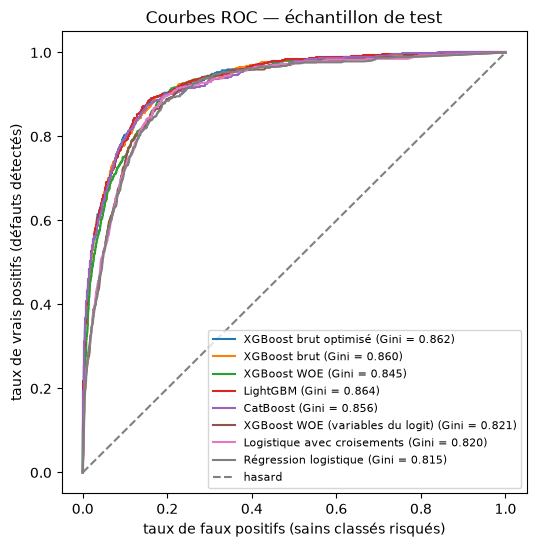

In [14]:
# Cellule 9 — comparaison des modèles sur le test : intervalles de confiance par bootstrap (par client) et courbes ROC
import matplotlib.pyplot as plt

X_test_woe = models.matrice_xgb(test, VARS_MODELE, regles, TARGET, "woe", ref=train)

# Diagnostic : XGBoost sur la WOE des seules variables du logit (mêmes classes que la régression)
X_fit_wl, X_valid_wl, X_test_wl = (models.matrice_xgb(d, VARS_LOGIT, regles_modele, TARGET, "woe", ref=train)
                                   for d in (fit, valid, test))
xgb_woe_logit = models.entrainer_xgb(X_fit_wl, fit[TARGET], X_valid_wl, valid[TARGET])

SCORES = {
    "XGBoost brut optimisé": xgb_opt.predict_proba(X_test_brut)[:, 1],
    "XGBoost brut": modeles["brut"][0].predict_proba(X_test_brut)[:, 1],
    "XGBoost WOE": modeles["woe"][0].predict_proba(X_test_woe)[:, 1],
    "LightGBM": lgbm.predict_proba(X_test_brut)[:, 1],
    "CatBoost": catb.predict_proba(C_test)[:, 1],
    "XGBoost WOE (variables du logit)": xgb_woe_logit.predict_proba(X_test_wl)[:, 1],
    "Logistique avec croisements": models.predire(logit_croise, X_test_c),
    "Régression logistique": models.predire(logit, X_test_l),
}
gini_ic, ecarts_ic = models.gini_bootstrap(test[TARGET], SCORES, test[ID], reference="Régression logistique", n_tirages=1000)
print(gini_ic); print(ecarts_ic)
models.courbes_roc(test[TARGET], SCORES); plt.show()

**Résultats.** Tous les modèles XGBoost font significativement mieux que la régression logistique : l'intervalle de confiance de l'écart ne contient jamais 0. L'écart est de 4,5 à 4,7 points de Gini face aux versions sur valeurs brutes (IC à 95 % : environ [3,6 ; 5,7]) et de 3,0 points face à XGBoost sur la WOE des 37 variables ([2,3 ; 3,9]). Les intervalles individuels se chevauchent, mais la comparaison pertinente est celle de l'écart, calculé sur les mêmes tirages de clients.

**D'où vient l'écart ?** Les modèles de diagnostic le décomposent :

| Source | Écart de Gini | Mesure |
|---|---|---|
| Découpage fin des valeurs brutes | 1,5 pt | XGBoost brut − XGBoost WOE |
| Variables non retenues (27) | 2,4 pts | XGBoost WOE (37 variables) − XGBoost WOE (10 variables du logit) |
| Forme additive (non-linéarités et interactions) | 0,6 pt | XGBoost WOE (10 variables) − régression, IC [0,1 ; 1,1] |

Sur les mêmes variables et les mêmes classes, XGBoost ne fait presque pas mieux que la régression : la forme additive coûte peu, ce que confirme l'absence d'interaction utile (2.5 bis). L'essentiel de l'écart vient de l'information diffuse des 27 variables écartées, qu'XGBoost cumule mais dont aucune, prise une à une, n'apporte assez à la régression (gain inférieur à 0,2 point ou coefficients incohérents, voir les deux passages du stepwise), et du découpage plus fin des valeurs.

Cet écart, réel mais modéré, est le prix de l'interprétabilité : la régression logistique se traduit en une grille de points lisible, dont chaque coefficient est justifiable, ce qui est exigé en scoring réglementaire. Avec 470 défauts dans le test, le Gini de chaque modèle est connu à environ ± 2,5 points près ; des écarts inférieurs au point entre variantes d'un même modèle ne sont donc pas interprétables.

**Importance par permutation (10.1).** Pour chaque variable, on mélange ses valeurs sur le test (le lien avec le défaut est rompu, la distribution conservée) et on mesure la **perte de Gini**, en moyenne sur 10 tirages. Contrairement à SHAP, propre à XGBoost, la méthode s'applique à tout modèle et s'exprime en points de Gini : on compare directement ce que chaque variable apporte à XGBoost et à la régression. Les variables importantes pour XGBoost mais absentes de la régression indiquent où se trouve l'écart de performance.

In [15]:
# Cellule 9 bis — importance par permutation sur le test : régression logistique et XGBoost
pred_logit = lambda d: models.predire(logit, models.matrice_indicatrices(d, VARS_LOGIT, regles_modele, ORDRES)[0])
pred_xgb = lambda d: xgb_opt.predict_proba(models.matrice_xgb(d, VARS_MODELE, regles, TARGET, "brut", ref=train))[:, 1]
perm_logit = models.importance_permutation(test, VARS_LOGIT, TARGET, pred_logit)
perm_xgb = models.importance_permutation(test, VARS_MODELE, TARGET, pred_xgb)

importance = (perm_xgb.select("variable", pl.col("perte_gini").alias("perm_xgb"), pl.col("ecart_type").alias("ecart_type_xgb"))
              .join(perm_logit.select("variable", pl.col("perte_gini").alias("perm_logit")), on="variable", how="left")
              .join(shap.select("variable", "part_shap"), on="variable", how="left")
              .with_columns(dans_logit=pl.col("variable").is_in(VARS_LOGIT)))
print(importance)

shape: (37, 6)
┌───────────────────────────────┬───────────┬────────────────┬────────────┬───────────┬────────────┐
│ variable                      ┆ perm_xgb  ┆ ecart_type_xgb ┆ perm_logit ┆ part_shap ┆ dans_logit │
╞═══════════════════════════════╪═══════════╪════════════════╪════════════╪═══════════╪════════════╡
│ ARR_GDT                       ┆ 0.015731  ┆ 0.001275       ┆ 0.011698   ┆ 0.066277  ┆ true       │
│ bilan                         ┆ 0.007463  ┆ 0.001843       ┆ null       ┆ 0.07665   ┆ false      │
│ TX_UTIL_DAV                   ┆ 0.006411  ┆ 0.001797       ┆ 0.015863   ┆ 0.08043   ┆ true       │
│ MINSOLDE_PAR                  ┆ 0.005348  ┆ 0.003441       ┆ 0.018109   ┆ 0.111209  ┆ true       │
│ horsbilan                     ┆ 0.004867  ┆ 0.00142        ┆ 0.006399   ┆ 0.062767  ┆ true       │
│ anciennete_jour_sain_M0       ┆ 0.004644  ┆ 0.000957       ┆ 0.006347   ┆ 0.045755  ┆ true       │
│ engagement                    ┆ 0.004342  ┆ 0.000839       ┆ null       ┆ 

## 2.6 bis Reproduire XGBoost avec la régression logistique

L'importance par permutation montre où XGBoost prend son avance : des variables écartées par le stepwise (`bilan`, `engagement`, `CRTAD_AG_NBJDE_BB`…), le plus souvent pour **coefficients incohérents**, et un usage plus fin des variables clés (`ARR_GDT` n'a que 2 classes dans la régression). Deux leviers sont testés, en restant dans le cadre d'une grille de score :

1. **Sélection guidée par XGBoost** : les variables hors modèle sont essayées dans l'ordre de leur importance par permutation pour XGBoost. Quand les coefficients d'une variable sont incohérents, les deux classes inversées sont **fusionnées** (regroupement du 5.1) et la variable est réessayée, jusqu'à 5 fois, au lieu d'être écartée. Le seuil de gain est abaissé à 0,1 point de Gini de validation.
2. **Découpage plus fin** des quatre variables les plus importantes pour XGBoost : part minimale de 3 % au lieu de 5 % par classe, monotonie et écart de 30 % chaque mois maintenus. Les variables sont ensuite réintroduites avec la même procédure.
3. **Découpage optimal de toutes les variables** (`optbinning`) : pour chaque variable numérique, les bornes qui maximisent l'IV sous contraintes (3 % de population et 20 défauts par classe, monotonie), puis la fusion habituelle (écart de 30 % chaque mois) et l'arrondi des bornes. La sélection guidée repart de zéro, sur les 37 variables, dans l'ordre de l'importance par permutation de XGBoost.

Pour chaque variante, le **test par modalité** (5.1) est ensuite appliqué comme en 2.5 : une modalité non significative est fusionnée avec sa voisine moins risquée, et le modèle réestimé, jusqu'à ce que toutes soient significatives.

La sélection se fait sur l'échantillon de validation ; le test ne sert qu'à la comparaison finale, avec intervalles de confiance par bootstrap.

In [16]:
# Cellule 9 ter — levier 1 : sélection guidée par l'importance par permutation de XGBoost
HORS_LOGIT = perm_xgb.filter(~pl.col("variable").is_in(VARS_LOGIT) & (pl.col("perte_gini") > 0))["variable"].to_list()
VARS_GUIDE, regles_guide, journal_guide = models.stepwise_guide(
    fit, valid, VARS_LOGIT, HORS_LOGIT, regles | regles_modele, TARGET, alpha=0.05, gain_gini_min=0.001)
print(len(VARS_GUIDE), "variables :", VARS_GUIDE)
print(journal_guide)

11 variables : ['horsbilan', 'solde_crediteur', 'TX_UTIL_DAV', 'ARR_GDT', 'MINSOLDE_PAR', 'CRTAE_AG_SLDEPA', 'ARR_TENDANCE', 'anciennete_jour_sain_M0', 'RATIO_ECR', 'CODITDBDF_PAR', 'bilan']
shape: (25, 8)
┌───────────────────────────────┬───────────┬───────────┬────────────┬────────────┬───────────┬──────────┬─────────────────────────────────┐
│ variable                      ┆ n_fusions ┆ n_classes ┆ p_lr       ┆ gini_valid ┆ gain_gini ┆ decision ┆ motif                           │
╞═══════════════════════════════╪═══════════╪═══════════╪════════════╪════════════╪═══════════╪══════════╪═════════════════════════════════╡
│ bilan                         ┆ 0         ┆ 2         ┆ 0.000003   ┆ 0.834391   ┆ 0.00285   ┆ retenue  ┆                                 │
│ engagement                    ┆ 1         ┆ 2         ┆ 0.14692    ┆ 0.834387   ┆ -0.000004 ┆ écartée  ┆ non significative (p = 0.147)   │
│ CRTAD_AG_NBJDE_BB             ┆ 2         ┆ 2         ┆ 0.134204   ┆ 0.835859   ┆ 0.001

In [17]:
# Cellule 9 quater — levier 2 : découpage plus fin des variables clés de XGBoost, puis réintroduction
FINES = perm_xgb["variable"].head(4).to_list()
regles_fines = {v: binning.arrondir_bornes(binning.regle_par_methode(
    train, v, TARGET, regles[v].get("methode", "quantiles").split(" ")[0], DATE, part_min=0.03)) for v in FINES}
print(pl.DataFrame({"variable": FINES, "classes_avant": [len(regles[v]["bornes"]) + 1 for v in FINES],
                    "classes_fines": [len(regles_fines[v]["bornes"]) + 1 for v in FINES]}))

VARS_FIN, regles_fin, journal_fin = models.stepwise_guide(
    fit, valid, [v for v in VARS_GUIDE if v not in FINES], FINES, regles_guide | regles_fines, TARGET,
    alpha=0.05, gain_gini_min=0.001)
print(len(VARS_FIN), "variables :", VARS_FIN)
print(journal_fin)

shape: (4, 3)
┌──────────────┬───────────────┬───────────────┐
│ variable     ┆ classes_avant ┆ classes_fines │
╞══════════════╪═══════════════╪═══════════════╡
│ ARR_GDT      ┆ 2             ┆ 3             │
│ bilan        ┆ 2             ┆ 2             │
│ TX_UTIL_DAV  ┆ 4             ┆ 4             │
│ MINSOLDE_PAR ┆ 3             ┆ 3             │
└──────────────┴───────────────┴───────────────┘
10 variables : ['horsbilan', 'solde_crediteur', 'CRTAE_AG_SLDEPA', 'ARR_TENDANCE', 'anciennete_jour_sain_M0', 'RATIO_ECR', 'CODITDBDF_PAR', 'ARR_GDT', 'bilan', 'TX_UTIL_DAV']
shape: (4, 8)
┌──────────────┬───────────┬───────────┬────────────┬────────────┬───────────┬──────────┬─────────────────────────────────┐
│ variable     ┆ n_fusions ┆ n_classes ┆ p_lr       ┆ gini_valid ┆ gain_gini ┆ decision ┆ motif                           │
╞══════════════╪═══════════╪═══════════╪════════════╪════════════╪═══════════╪══════════╪═════════════════════════════════╡
│ ARR_GDT      ┆ 1         ┆ 2   

In [18]:
# Cellule 9 quater bis — levier 3 : découpage optimal (optbinning) de toutes les variables numériques, sélection guidée
NUMERIQUES = [v for v in VARS_MODELE if regles[v]["type"] == "num"]
regles_opt = {v: binning.arrondir_bornes(binning.regle_par_methode(train, v, TARGET, "optbinning", DATE, part_min=0.03))
              for v in NUMERIQUES}
print(pl.DataFrame({"variable": NUMERIQUES, "classes_avant": [len(regles[v]["bornes"]) + 1 for v in NUMERIQUES],
                    "classes_optbinning": [len(regles_opt[v]["bornes"]) + 1 for v in NUMERIQUES],
                    "bornes_optbinning": [str(regles_opt[v]["bornes"]) for v in NUMERIQUES]}))

VARS_OPT, regles_opt_sel, journal_opt = models.stepwise_guide(
    fit, valid, [], perm_xgb["variable"].to_list(), regles | regles_opt, TARGET, alpha=0.05, gain_gini_min=0.001)
print(len(VARS_OPT), "variables :", VARS_OPT)
print(journal_opt)

shape: (34, 4)
┌───────────────────────────────┬───────────────┬────────────────────┬─────────────────────────────────┐
│ variable                      ┆ classes_avant ┆ classes_optbinning ┆ bornes_optbinning               │
╞═══════════════════════════════╪═══════════════╪════════════════════╪═════════════════════════════════╡
│ horsbilan                     ┆ 3             ┆ 2                  ┆ [40.0]                          │
│ solde_crediteur               ┆ 5             ┆ 5                  ┆ [650.0, 5500.0, 18000.0, 57000… │
│ TX_UTIL_DAV                   ┆ 4             ┆ 4                  ┆ [1.0, 3.7, 19.0]                │
│ ARR_GDT                       ┆ 2             ┆ 2                  ┆ [24.0]                          │
│ MINSOLDE_PAR                  ┆ 3             ┆ 4                  ┆ [2700.0, 15000.0, 37000.0]      │
│ CRTAD_AG_NBJDE_BB             ┆ 4             ┆ 5                  ┆ [4.5, 16.0, 64.0, 82.0]         │
│ bilan                         ┆ 2     

In [19]:
# Cellule 9 quinquies — comparaison sur le test : variantes de régression contre logit actuel et XGBoost
VARIANTES = {"Logit actuel": (VARS_LOGIT, regles_modele), "Logit guidé": (VARS_GUIDE, regles_guide),
             "Logit guidé + découpage fin": (VARS_FIN, regles_fin), "Logit optbinning guidé": (VARS_OPT, regles_opt_sel)}

# Test par modalité (5.1), comme en 2.5 : modalités non significatives fusionnées avec leur voisine moins risquée
for nom in list(VARIANTES)[1:]:
    vs, r = VARIANTES[nom]
    r, journal_mod = models.regrouper_non_significatives(train, vs, r, TARGET)
    VARIANTES[nom] = (vs, r)
    if journal_mod.height:
        print(nom, "— regroupements :"); print(journal_mod)
finaux, lignes = {}, []
for nom, (vs, r) in VARIANTES.items():
    finaux[nom] = f = models.logit_final(train, test, vs, r, TARGET, ID)
    lignes.append({"modele": nom, "variables": len(vs), "indicatrices": len(f["noms"]), "coherent": f["coherent"],
                   "gini_train": models.metriques(train[TARGET], models.predire(f["res"], f["X_train"]))["gini"],
                   "gini_test": models.metriques(test[TARGET], models.predire(f["res"], f["X_test"]))["gini"]})
print(pl.DataFrame(lignes))

SCORES_LR = {nom: models.predire(f["res"], f["X_test"]) for nom, f in finaux.items()}
SCORES_LR["XGBoost brut optimisé"] = SCORES["XGBoost brut optimisé"]
gini_lr, ecarts_lr = models.gini_bootstrap(test[TARGET], SCORES_LR, test[ID], reference="Logit actuel", n_tirages=1000)
print(gini_lr); print(ecarts_lr)

Logit guidé — regroupements :
shape: (1, 5)
┌─────────────────┬───────────────┬────────────────┬──────────┬────────┐
│ variable        ┆ modalite      ┆ fusionnee_avec ┆ p_value  ┆ fusion │
╞═════════════════╪═══════════════╪════════════════╪══════════╪════════╡
│ solde_crediteur ┆ ]1600 ; 5500] ┆ ]5500 ; +inf]  ┆ 0.108078 ┆ true   │
└─────────────────┴───────────────┴────────────────┴──────────┴────────┘
Logit guidé + découpage fin — regroupements :
shape: (1, 5)
┌─────────────┬───────────┬────────────────┬──────────┬────────┐
│ variable    ┆ modalite  ┆ fusionnee_avec ┆ p_value  ┆ fusion │
╞═════════════╪═══════════╪════════════════╪══════════╪════════╡
│ TX_UTIL_DAV ┆ ]1 ; 3.7] ┆ ]-inf ; 1]     ┆ 0.241007 ┆ true   │
└─────────────┴───────────┴────────────────┴──────────┴────────┘
Logit optbinning guidé — regroupements :
shape: (3, 5)
┌─────────────────────────┬─────────────────┬────────────────┬──────────┬────────┐
│ variable                ┆ modalite        ┆ fusionnee_avec ┆ p_val

**Contrôles de la variante candidate.** Avant de remplacer le modèle, la variante choisie (`CANDIDAT`) passe les mêmes contrôles que le modèle de la section 2.4 : nouvelles bornes, tests par variable (rapport de vraisemblance et Wald robuste), test par modalité et odds ratios, VIF, et stabilité mensuelle (risque et volume) des variables dont le découpage a changé.

In [20]:
# Cellule 9 sexies — contrôles de la variante candidate (mêmes diagnostics qu'en 2.4 et 2.5)
CANDIDAT = "Logit guidé + découpage fin"
f = finaux[CANDIDAT]
CHANGEES = [v for v in VARIANTES[CANDIDAT][0] if f["regles"][v] != regles_modele.get(v)]
for v in CHANGEES:
    avant, apres = regles_modele.get(v), f["regles"][v]
    print(f"{v} | avant : {avant.get('bornes', avant.get('groupes')) if avant else 'absente du modèle'} | après : {apres.get('bornes', apres.get('groupes'))}")
print("sortie(s) du modèle :", [v for v in VARS_LOGIT if v not in VARIANTES[CANDIDAT][0]])

print(models.tests_par_variable(f["res"], f["X_train"], train[TARGET], f["groupes"]))
odds = models.odds_ratios(f["res"], f["noms"])
print(odds)
print("modalités non significatives (p > 5 %) :", odds.filter((pl.col("p_value") > 0.05) & (pl.col("terme") != "constante"))["terme"].to_list())
print(models.vif_indicatrices(f["X_train"], f["noms"]).head(5))
for v in CHANGEES:
    print(v, "| PSI maximal entre mois :", round(binning.psi_mensuel(train, v, f["regles"][v], DATE), 4))
    print(binning.stabilite_regle(train, v, TARGET, DATE, f["regles"][v]))

ARR_GDT | avant : [3.0] | après : [68.0]
bilan | avant : absente du modèle | après : [0.0]
TX_UTIL_DAV | avant : [3.7, 19.0] | après : [3.7, 19.0]
sortie(s) du modèle : ['MINSOLDE_PAR']
shape: (10, 6)
┌─────────────────────────┬─────┬────────────┬────────────┬────────────┬────────────┐
│ variable                ┆ ddl ┆ lr         ┆ p_lr       ┆ wald       ┆ p_wald     │
╞═════════════════════════╪═════╪════════════╪════════════╪════════════╪════════════╡
│ ARR_GDT                 ┆ 1   ┆ 312.338362 ┆ 6.7583e-70 ┆ 291.98875  ┆ 1.8333e-65 │
│ ARR_TENDANCE            ┆ 2   ┆ 132.265627 ┆ 1.9006e-29 ┆ 110.421262 ┆ 1.0528e-24 │
│ solde_crediteur         ┆ 3   ┆ 116.081701 ┆ 5.3851e-25 ┆ 108.201164 ┆ 2.6757e-23 │
│ CRTAE_AG_SLDEPA         ┆ 3   ┆ 80.14963   ┆ 2.8506e-17 ┆ 61.270036  ┆ 3.1468e-13 │
│ anciennete_jour_sain_M0 ┆ 3   ┆ 69.534947  ┆ 5.3683e-15 ┆ 62.558357  ┆ 1.6691e-13 │
│ CODITDBDF_PAR           ┆ 1   ┆ 62.952783  ┆ 2.1172e-15 ┆ 60.331406  ┆ 8.0158e-15 │
│ TX_UTIL_DAV            

**Modèle final.** Si les contrôles sont satisfaisants, la variante remplace le modèle de la section 2.4 : la grille de score (2.7) et la base exportée pour les CHR sont construites à partir d'elle. Pour revenir au modèle initial, il suffit de remettre `MODELE_FINAL = "Logit actuel"`.

In [21]:
# Cellule 9 septies — choix du modèle final
MODELE_FINAL = CANDIDAT
f = finaux[MODELE_FINAL]
VARS_LOGIT = VARIANTES[MODELE_FINAL][0]
logit, X_train_l, X_test_l = f["res"], f["X_train"], f["X_test"]
regles_modele, ORDRES, GROUPES, NOMS = f["regles"], f["ordres"], f["groupes"], f["noms"]
binning.sauver_regles(regles_modele, f"outputs/scorecard/regles_modele_{CODE}.json")
print(MODELE_FINAL, "|", len(VARS_LOGIT), "variables :", VARS_LOGIT)
print(pl.DataFrame([models.metriques(train[TARGET], models.predire(logit, X_train_l), "train"),
                    models.metriques(test[TARGET], models.predire(logit, X_test_l), "test")]).select("echantillon", "gini", "ks"))

Logit guidé + découpage fin | 10 variables : ['horsbilan', 'solde_crediteur', 'CRTAE_AG_SLDEPA', 'ARR_TENDANCE', 'anciennete_jour_sain_M0', 'RATIO_ECR', 'CODITDBDF_PAR', 'ARR_GDT', 'bilan', 'TX_UTIL_DAV']
shape: (2, 3)
┌─────────────┬──────────┬──────────┐
│ echantillon ┆ gini     ┆ ks       │
╞═════════════╪══════════╪══════════╡
│ train       ┆ 0.841418 ┆ 0.694851 │
│ test        ┆ 0.825108 ┆ 0.70182  │
└─────────────┴──────────┴──────────┘


### Effet des variables : XGBoost comparé à la grille (10.1)

Le **graphique de dépendance SHAP** est agrégé : la variable est découpée en 40 tranches de même effectif et, pour chacune, on trace la contribution moyenne de la variable au log-odds prédit par XGBoost (ligne bleue) et ses quartiles (bande). Les sauts de la courbe indiquent les seuils où XGBoost voit le risque changer. Pour les variables de la grille, on superpose ses **bornes** (pointillés) et son **effet** (en rouge : coefficient moyen des clients de la tranche, centré), sur la même échelle du log-odds. Un saut de XGBoost sans borne de la grille signale un seuil manquant ; un écart de niveau, une information que la grille ne capte pas.

Le **graphique de dépendance partielle à deux variables** montre la probabilité de défaut moyenne prédite par XGBoost selon deux variables à la fois : si l'effet de l'une dépend du niveau de l'autre, les courbes de niveau ne sont pas parallèles (interaction).

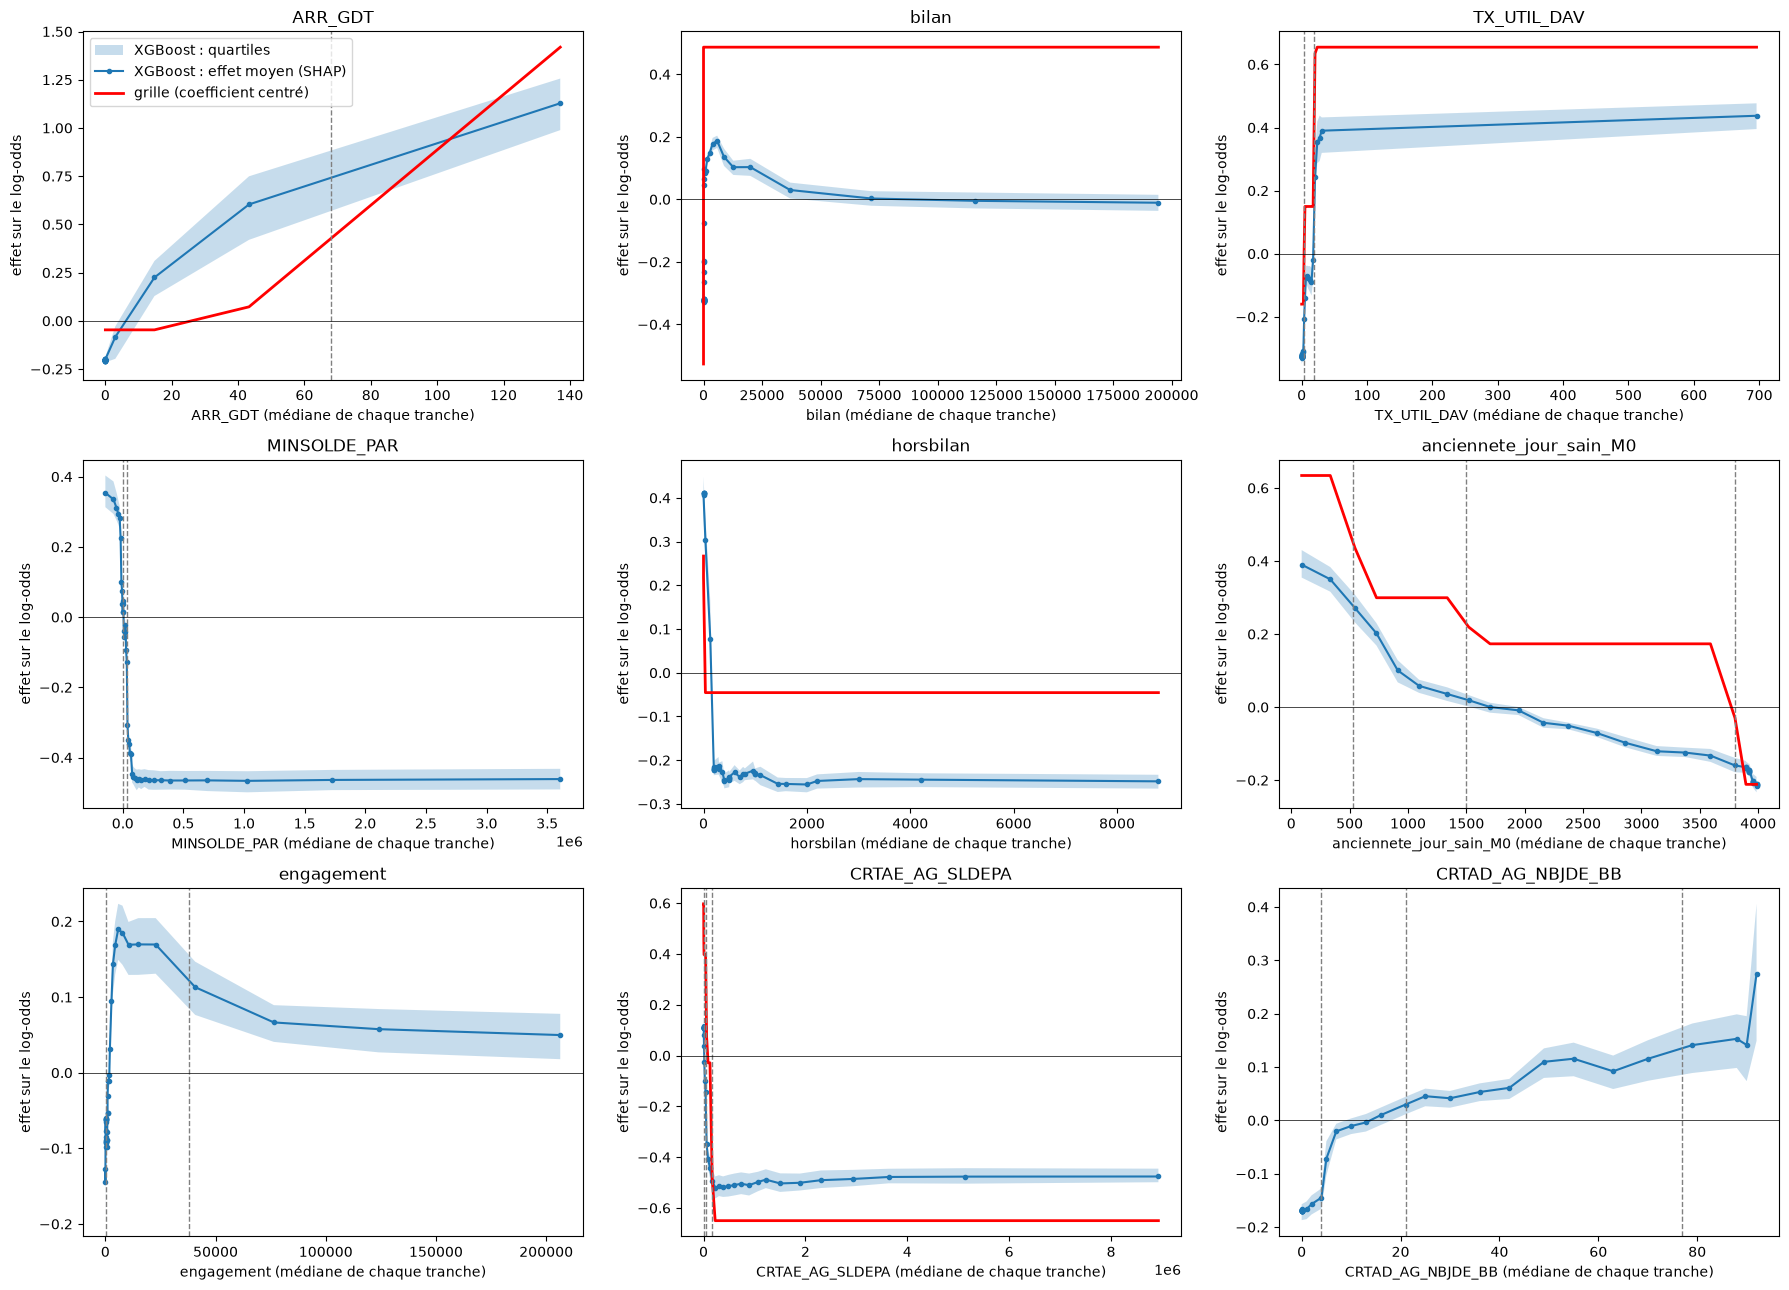

In [22]:
# Cellule 9 septies bis — dépendance SHAP des 9 variables numériques les plus importantes pour XGBoost, comparée à la grille
import matplotlib.pyplot as plt
from utils import scorecard

shap_test = models.valeurs_shap(xgb_opt, X_test_brut)
coefs_grille = scorecard._coefficients(logit, GROUPES, ORDRES)
A_TRACER = [v for v in perm_xgb["variable"].to_list() if regles[v]["type"] == "num"][:9]
fig, axes = plt.subplots(3, 3, figsize=(18, 13))
for ax, v in zip(axes.flat, A_TRACER):
    cc = (dict(coefs_grille.filter(pl.col("variable") == v).select("classe", "coefficient").iter_rows())
          if v in VARS_LOGIT else None)
    models.graphique_dependance(test, v, shap_test[:, VARS_MODELE.index(v)], regles_modele.get(v, regles[v]), cc, ax=ax)
axes.flat[0].legend()
plt.tight_layout(); plt.show()

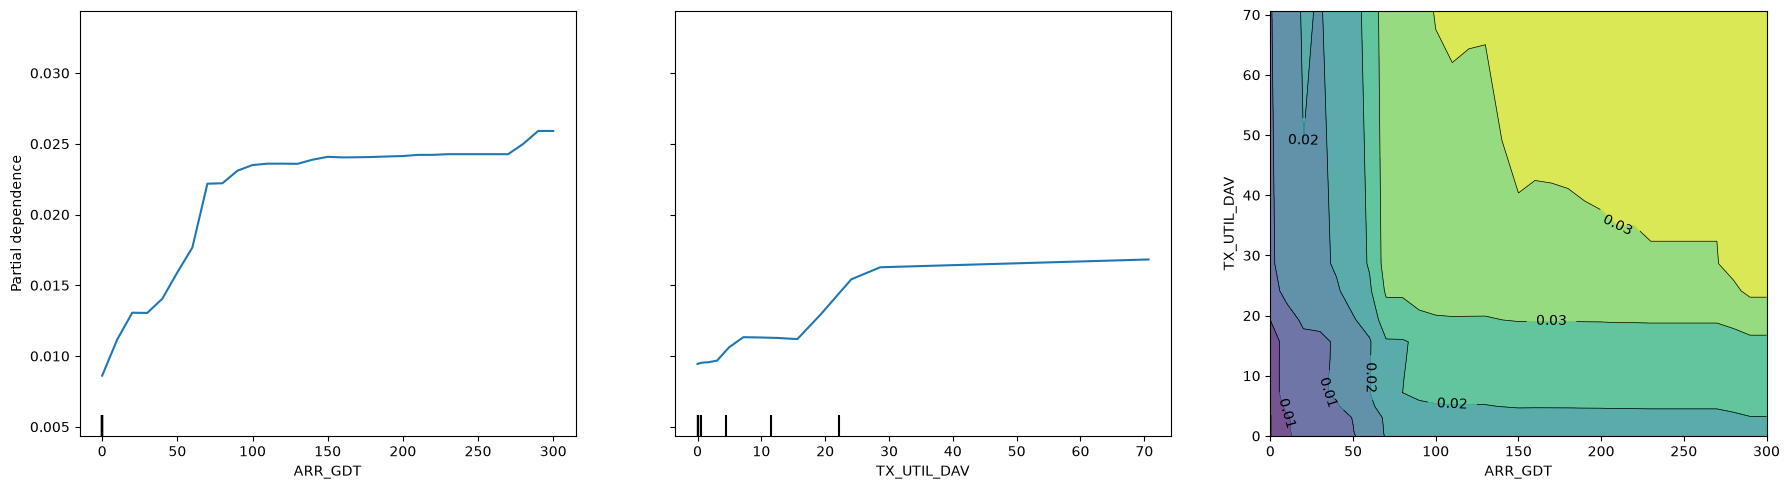

In [23]:
# Cellule 9 septies ter — dépendance partielle à deux variables (interaction) : ARR_GDT et TX_UTIL_DAV
from sklearn.inspection import PartialDependenceDisplay
import numpy as np

i_arr, i_tx = VARS_MODELE.index("ARR_GDT"), VARS_MODELE.index("TX_UTIL_DAV")
complet_2v = ~np.isnan(X_test_brut[:, [i_arr, i_tx]]).any(axis=1)
X_ech = X_test_brut[complet_2v][np.random.default_rng(0).choice(complet_2v.sum(), 5000, replace=False)]
fig, ax = plt.subplots(figsize=(18, 5))
# grilles adaptées : ARR_GDT de 0 à 300 ; TX_UTIL_DAV sur ses quantiles jusqu'à 98 % (quelques valeurs extrêmes écrasent l'échelle)
GRILLES = {i_arr: np.linspace(0, 300, 31),
           i_tx: np.unique(np.quantile(X_ech[:, i_tx], np.linspace(0, 0.98, 30)))}
PartialDependenceDisplay.from_estimator(xgb_opt, X_ech, features=[i_arr, i_tx, (i_arr, i_tx)], feature_names=VARS_MODELE,
                                        custom_values=GRILLES, ax=ax)
plt.tight_layout(); plt.show()

## 2.6 ter Sous-segmentation de SB

Une grille unique applique les mêmes points à tous les clients. Si deux sous-populations ont des risk drivers différents (par exemple les clients en arriérés importants et les autres), une **grille par sous-population** capte ces différences, ce que XGBoost fait par ses interactions, tout en restant une grille de points (1.4).

**Coupures candidates.** Trois sources : des coupures choisies pour leur sens métier ; pour les variables les plus importantes de XGBoost, des seuils aux quantiles (10 %, 25 %, 50 %, 75 %, 90 %) ; et les coupures d'un **arbre ajusté sur les erreurs du modèle unique** (défaut observé − PD prédite), qui désignent les zones où la grille unique se trompe le plus, donc les interactions qu'elle ne capte pas.

**Criblage.** Toutes les coupures sont d'abord criblées rapidement : les variables du modèle unique sont conservées et seuls leurs coefficients diffèrent entre les deux sous-populations (test de Chow : rapport de vraisemblance entre les deux modèles et le modèle unique). Les 5 coupures qui réduisent le plus l'AIC tout en améliorant le Gini de validation passent à l'étape suivante.

**Modélisation complète.** Pour chacune de ces coupures, un modèle est construit sur chaque sous-population avec la même procédure que le modèle final (sélection guidée, regroupement des classes incohérentes, test par modalité), sur l'échantillon d'estimation. Les prédictions des deux modèles sont assemblées sur la validation et comparées au modèle unique :
- **Gini de validation global** : capacité à classer l'ensemble des clients ;
- **AIC** (somme des AIC des deux modèles) : qualité d'ajustement pénalisée par le nombre de paramètres ;
- une sous-population doit compter au moins 200 défauts d'estimation, sinon son modèle serait trop fragile.

La coupure retenue doit améliorer **à la fois** le Gini de validation et l'AIC (tester beaucoup de coupures rend le meilleur Gini de validation optimiste ; l'AIC sert de garde-fou). Elle est ensuite mesurée une seule fois sur le test, avec intervalles de confiance par bootstrap. Une coupure sur une variable déjà présente dans le modèle ajoute mécaniquement un seuil à cette variable : une partie du gain éventuel peut venir de ce seuil plutôt que de risk drivers propres à chaque sous-population ; la composition des deux modèles permet d'en juger.

In [24]:
# Cellule 9 octies — sous-segmentation : génération et criblage des coupures candidates (estimation / validation)
import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # essais sur de petites sous-populations ; les modèles retenus sont contrôlés

REFERENCE = (VARS_LOGIT, regles_modele)
COUPURES = {                                                       # coupures métier
    "ARR_GDT > 68": pl.col("ARR_GDT") > 68,
    "TX_UTIL_DAV > 19": pl.col("TX_UTIL_DAV") > 19,
    "solde_crediteur ≤ 0": pl.col("solde_crediteur") <= 0,
    "horsbilan ≤ 0": pl.col("horsbilan") <= 0,
}
NUM_TOP = [v for v in perm_xgb["variable"].head(8).to_list() if regles[v]["type"] == "num"]
COUPURES |= models.coupures_quantiles(fit, NUM_TOP)                # seuils aux quantiles
pd_fit_ref = models.predire_sous_population(fit, fit, *REFERENCE, TARGET)[0]
COUPURES |= models.coupures_arbre_residus(fit, pd_fit_ref, VARS_MODELE, TARGET, profondeur=2)   # erreurs du modèle unique

criblage = models.cribler_coupures(fit, valid, COUPURES, REFERENCE, TARGET, defauts_min=200)
print(len(COUPURES), "coupures candidates |", criblage.height, "avec au moins 200 défauts d'estimation de chaque côté")
print(criblage.head(15))

32 coupures candidates | 13 avec au moins 200 défauts d'estimation de chaque côté
shape: (13, 9)
┌────────────────────────────────┬──────────┬───────────┬───────────┬────────────┬───────────┬─────────────┬────────────┬────────────┐
│ coupure                        ┆ part_a   ┆ defauts_a ┆ defauts_b ┆ gini_valid ┆ gain_gini ┆ aic         ┆ delta_aic  ┆ p_chow     │
╞════════════════════════════════╪══════════╪═══════════╪═══════════╪════════════╪═══════════╪═════════════╪════════════╪════════════╡
│ MINSOLDE_PAR > -30000          ┆ 0.899914 ┆ 579       ┆ 291       ┆ 0.841074   ┆ 0.002585  ┆ 6370.073427 ┆ -46.944683 ┆ 2.5751e-10 │
│ engagement > 200               ┆ 0.804524 ┆ 584       ┆ 286       ┆ 0.836516   ┆ -0.001973 ┆ 6379.342097 ┆ -37.676013 ┆ 1.0221e-8  │
│ engagement > 800               ┆ 0.497553 ┆ 389       ┆ 481       ┆ 0.835478   ┆ -0.003011 ┆ 6384.025668 ┆ -32.992442 ┆ 6.2862e-8  │
│ engagement > 300               ┆ 0.749919 ┆ 524       ┆ 346       ┆ 0.836522   ┆ -0.001967 

In [25]:
# Cellule 9 octies bis — modélisation complète des 5 meilleures coupures du criblage
regles_ss = regles | VARIANTES[MODELE_FINAL][1]
RETENUES = criblage.filter((pl.col("gain_gini") > 0) & (pl.col("delta_aic") < 0)).head(5)["coupure"].to_list()
comparaison_ss, SOUS_MODELES = models.comparer_sous_segmentations(
    fit, valid, {k: COUPURES[k] for k in RETENUES}, perm_xgb["variable"].to_list(), regles_ss, TARGET, REFERENCE, defauts_min=200)
print(comparaison_ss)
for nom, sm in SOUS_MODELES.items():
    print(f"{nom}\n  A ({len(sm['a'][0])} var.) : {sm['a'][0]}\n  B ({len(sm['b'][0])} var.) : {sm['b'][0]}")

shape: (4, 10)
┌───────────────────────┬──────────┬───────────┬───────────┬─────────────┬─────────────┬────────────┬─────────────┬──────────────┬──────────────┐
│ coupure               ┆ part_a   ┆ defauts_a ┆ defauts_b ┆ variables_a ┆ variables_b ┆ gini_valid ┆ aic         ┆ gini_valid_a ┆ gini_valid_b │
╞═══════════════════════╪══════════╪═══════════╪═══════════╪═════════════╪═════════════╪════════════╪═════════════╪══════════════╪══════════════╡
│ modèle unique         ┆ null     ┆ 870       ┆ null      ┆ 10          ┆ null        ┆ 0.838489   ┆ 6417.01811  ┆ null         ┆ null         │
│ MINSOLDE_PAR > -30000 ┆ 0.899914 ┆ 579       ┆ 291       ┆ 12          ┆ 11          ┆ 0.840495   ┆ 6368.419803 ┆ 0.849829     ┆ 0.660089     │
│ ARR_GDT > 68          ┆ 0.030969 ┆ 361       ┆ 509       ┆ 9           ┆ 12          ┆ 0.846923   ┆ 6311.594468 ┆ 0.569348     ┆ 0.789101     │
│ bilan > 2300          ┆ 0.250603 ┆ 245       ┆ 625       ┆ 11          ┆ 10          ┆ 0.834919   ┆ 6410.78

In [26]:
# Cellule 9 nonies — meilleure coupure (Gini de validation et AIC), réestimée sur tout l'apprentissage et mesurée sur le test
unique = comparaison_ss.filter(pl.col("coupure") == "modèle unique").row(0, named=True)
eligibles = comparaison_ss.filter((pl.col("coupure") != "modèle unique") & (pl.col("gini_valid") > unique["gini_valid"])
                                  & (pl.col("aic") < unique["aic"])).sort("gini_valid", descending=True)
assert eligibles.height, "aucune coupure n'améliore à la fois le Gini de validation et l'AIC"
COUPURE = eligibles["coupure"][0]
print("coupure retenue :", COUPURE)
ss = models.logit_sous_segmente(train, test, SOUS_MODELES[COUPURE], TARGET, ID)
for k in ("a", "b"):
    f_k = ss["finaux"][k]
    print(f"{COUPURE} — sous-population {k.upper()} : {len(f_k['noms'])} indicatrices, coefficients cohérents : {f_k['coherent']}")

SCORES_SS = {"Modèle unique (final)": models.predire(logit, X_test_l), f"Sous-segmentation {COUPURE}": ss["pd_test"],
             "XGBoost brut optimisé": SCORES["XGBoost brut optimisé"]}
gini_ss, ecarts_ss = models.gini_bootstrap(test[TARGET], SCORES_SS, test[ID], reference="Modèle unique (final)", n_tirages=1000)
print(gini_ss); print(ecarts_ss)

coupure retenue : ARR_GDT > 68


ARR_GDT > 68 — sous-population A : 13 indicatrices, coefficients cohérents : True
ARR_GDT > 68 — sous-population B : 17 indicatrices, coefficients cohérents : True
shape: (3, 4)
┌────────────────────────────────┬──────────┬──────────┬──────────┐
│ modele                         ┆ gini     ┆ ic_bas   ┆ ic_haut  │
╞════════════════════════════════╪══════════╪══════════╪══════════╡
│ Modèle unique (final)          ┆ 0.825108 ┆ 0.796312 ┆ 0.850525 │
│ Sous-segmentation ARR_GDT > 68 ┆ 0.834301 ┆ 0.809202 ┆ 0.856296 │
│ XGBoost brut optimisé          ┆ 0.861868 ┆ 0.839323 ┆ 0.881624 │
└────────────────────────────────┴──────────┴──────────┴──────────┘
shape: (2, 6)
┌────────────────────────────────┬───────────────────────┬────────────┬───────────┬──────────┬──────────────┐
│ modele                         ┆ reference             ┆ ecart_gini ┆ ic_bas    ┆ ic_haut  ┆ significatif │
╞════════════════════════════════╪═══════════════════════╪════════════╪═══════════╪══════════╪══════════════╡
│ 

## 2.7 Grille de score 

La régression logistique donne, pour chaque client, une probabilité de défaut. Pour l'usage opérationnel, on la traduit en **grille de points** : chaque modalité de chaque variable vaut un nombre de points, et le **score** d'un client est la somme des points de ses modalités. Un score élevé signale un risque faible.

**Méthode PDO (Points to Double the Odds, 6.2).** On note cote = P(sain) / P(défaut). La méthode impose une relation linéaire entre le score et le logarithme de la cote :

$$\text{score} = \text{Offset} + \text{Factor} \times \ln(\text{cote})$$

Deux paramètres d'échelle, choisis par convention, fixent Factor et Offset :
- **PDO = 20** : la cote double tous les 20 points, d'où Factor = 20 / ln 2 ≈ 28,9 ;
- **score de référence = 600 pour une cote de 50 contre 1** (PD ≈ 2 %), d'où Offset = 600 − Factor × ln 50.

Comme la régression donne ln(cote) = −(β₀ + Σ βⱼ), chaque modalité reçoit −Factor × βⱼ points, plus une part égale de (Offset − Factor × β₀) répartie entre les variables. La classe de référence de chaque variable (la moins risquée) reçoit le maximum de points ; chaque classe plus risquée en reçoit moins, proportionnellement à son coefficient. La grille PDO conserve exactement l'information du modèle : un score se reconvertit en PD.

**Méthode par normalisation des coefficients (6.3).** Alternative plus intuitive : dans chaque variable, la classe la plus risquée vaut 0 point et la moins risquée le maximum ; les maxima sont proportionnels à l'étendue des coefficients et somment à 1 000. Le score va de 0 (pire profil) à 1 000 (meilleur profil), mais ne se relie pas directement à une PD.


In [27]:
# Cellule 10 — grilles de score PDO et normalisée, à partir du modèle final
from utils import scorecard

SCORE_REF, ODDS_REF, PDO = 600, 50, 20
FACTOR, OFFSET = scorecard.parametres_pdo(SCORE_REF, ODDS_REF, PDO)
print(f"Factor = {FACTOR:.2f} | Offset = {OFFSET:.2f}")

grille = scorecard.grille_pdo(logit, GROUPES, ORDRES, SCORE_REF, ODDS_REF, PDO)
grille_norm = scorecard.grille_normalisee(logit, GROUPES, ORDRES, total=1000)
grilles = grille.join(grille_norm.select("variable", "classe", pl.col("points").alias("points_normalises")),
                      on=["variable", "classe"])
print(grilles)


Factor = 28.85 | Offset = 487.12
shape: (28, 6)
┌─────────────────────────┬─────────────────────┬─────────────┬───────────┬────────┬───────────────────┐
│ variable                ┆ classe              ┆ coefficient ┆ reference ┆ points ┆ points_normalises │
╞═════════════════════════╪═════════════════════╪═════════════╪═══════════╪════════╪═══════════════════╡
│ horsbilan               ┆ ]0 ; +inf]          ┆ 0.0         ┆ true      ┆ 72     ┆ 33                │
│ horsbilan               ┆ ]-inf ; 0]          ┆ 0.312386    ┆ false     ┆ 63     ┆ 0                 │
│ solde_crediteur         ┆ ]5500 ; +inf]       ┆ 0.0         ┆ true      ┆ 72     ┆ 120               │
│ solde_crediteur         ┆ ]1600 ; 5500]       ┆ 0.368335    ┆ false     ┆ 61     ┆ 81                │
│ solde_crediteur         ┆ ]0 ; 1600]          ┆ 0.599186    ┆ false     ┆ 55     ┆ 57                │
│ solde_crediteur         ┆ ]-inf ; 0]          ┆ 1.139379    ┆ false     ┆ 39     ┆ 0                 │
│ CRTAE

In [28]:
# Cellule 11 — scores sur train et test : le passage en points doit conserver le pouvoir discriminant
score_train = scorecard.appliquer_grille(train, grille, regles_modele)
score_test = scorecard.appliquer_grille(test, grille, regles_modele)
score_test_norm = scorecard.appliquer_grille(test, grille_norm, regles_modele)
print(pl.DataFrame([
    models.metriques(test[TARGET], models.predire(logit, X_test_l), "Régression logistique (probabilité)"),
    models.metriques(test[TARGET], -score_test, "Grille PDO (points arrondis)"),
    models.metriques(test[TARGET], -score_test_norm, "Grille normalisée (points arrondis)"),
]).select("echantillon", "gini", "ks"))
print(f"Score PDO : de {score_train.min():.0f} à {score_train.max():.0f} (train)")


shape: (3, 3)
┌─────────────────────────────────┬──────────┬──────────┐
│ echantillon                     ┆ gini     ┆ ks       │
╞═════════════════════════════════╪══════════╪══════════╡
│ Régression logistique (probabi… ┆ 0.825108 ┆ 0.70182  │
│ Grille PDO (points arrondis)    ┆ 0.824759 ┆ 0.700359 │
│ Grille normalisée (points arro… ┆ 0.824887 ┆ 0.700252 │
└─────────────────────────────────┴──────────┴──────────┘
Score PDO : de 444 à 720 (train)


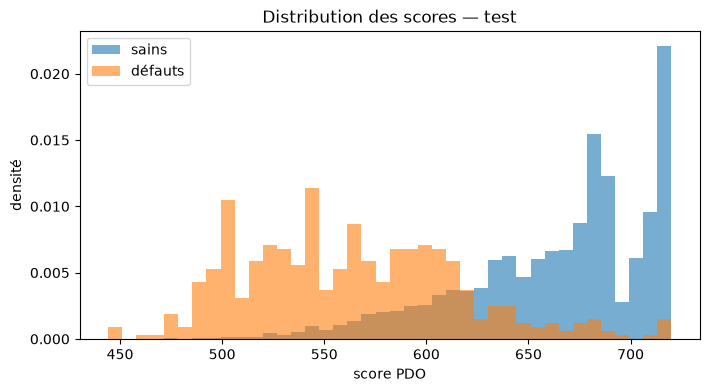

tranche,score_min,score_max,n,n_defaut,taux_defaut,part_defauts_cumulee
1,444.0,593.0,3799,332.0,0.087391,0.706383
2,593.0,624.0,3800,86.0,0.022632,0.889362
3,624.0,644.0,3799,21.0,0.005528,0.934043
4,644.0,661.0,3800,9.0,0.002368,0.953191
5,661.0,673.0,3800,4.0,0.001053,0.961702
6,673.0,684.0,3799,9.0,0.002369,0.980851
7,684.0,691.0,3800,2.0,0.000526,0.985106
8,691.0,709.0,3799,1.0,0.000263,0.987234
9,709.0,720.0,3800,5.0,0.001316,0.997872
10,720.0,720.0,3800,1.0,0.000263,1.0


In [29]:
# Cellule 12 — distribution des scores et taux de défaut par tranche de score (test)
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(score_test.filter(test[TARGET] == 0), bins=40, alpha=0.6, density=True, label="sains")
ax.hist(score_test.filter(test[TARGET] == 1), bins=40, alpha=0.6, density=True, label="défauts")
ax.set(xlabel="score PDO", ylabel="densité", title="Distribution des scores — test"); ax.legend(); plt.show()

scorecard.taux_par_tranche(score_test, test[TARGET], n_tranches=10)


**Résultats.** Avec PDO = 20 et 600 points pour une cote de 50 contre 1 (Factor = 28,85 ; Offset = 487,12), chaque classe de référence vaut 71 points et le meilleur profil possible totalise 710 points ; chaque classe plus risquée en vaut moins. Les plus fortes pénalités portent sur les arriérés récents ou récurrents (`ARR_TENDANCE`, 34 points au lieu de 71), l'incident Banque de France (37 au lieu de 71) et un solde d'épargne faible (42 au lieu de 71). Les scores observés vont de 466 (PD de 68 %) à 710 (PD de 0,04 %).

Le passage en points ne dégrade pas le pouvoir discriminant : Gini test de 0,815 pour la grille PDO comme pour la grille normalisée, identique à celui de la régression. Les deux méthodes classent les clients de la même façon ; la grille PDO est retenue car son échelle se relie directement à une PD (chaque tranche de 20 points double la cote), ce qui servira au calibrage.

Les défauts sont très concentrés dans les scores faibles : 70 % d'entre eux se trouvent dans les 10 % de scores les plus bas, et 88 % dans les 20 % les plus bas. Le taux de défaut décroît fortement sur les premières tranches (8,7 %, puis 2,2 %, puis 0,8 %) ; au-delà, il reste inférieur à 0,15 % et ne compte plus que quelques défauts par tranche, si bien que les écarts entre tranches n'y sont plus significatifs. Enfin, plus de 10 % des clients obtiennent le score maximal (classe de référence sur les dix variables) : le score ne distingue pas ces meilleurs profils entre eux, ce qui sera pris en compte dans la construction des classes homogènes de risque.

In [30]:
from utils import exploration
exploration.exporter_excel({f"{CODE}_Grille": grilles}, f"outputs/scorecard/grille_{CODE}.xlsx")


## Bilan des chapitres 5 et 6 pour le segment SB

| Modèle | Variables | Gini train | Gini test | IC à 95 % (test) |
|---|---|---|---|---|
| XGBoost, valeurs brutes, optimisé | 37 | 0,908 | 0,862 | [0,839 ; 0,882] |
| XGBoost, valeurs brutes | 37 | 0,895 | 0,860 | [0,838 ; 0,881] |
| XGBoost, WOE des classes | 37 | 0,868 | 0,845 | [0,822 ; 0,868] |
| **Régression logistique retenue** | **10 (19 indicatrices)** | **0,835** | **0,815** | **[0,790 ; 0,839]** |

La régression logistique retenue est **parcimonieuse** (10 variables), **cohérente** (tous les coefficients ordonnés selon le risque), **stable** (2 points d'écart entre apprentissage et test) et **proche du plafond de performance** (3 à 4,7 points de Gini de moins que XGBoost, écart significatif mais modéré). Elle repose sur quatre familles de risk drivers : les soldes et encours du compte, l'utilisation du découvert, les arriérés et l'historique de défaut, et l'activité du compte.

La **grille de score PDO** (PDO = 20, 600 points pour une cote de 50 contre 1) traduit le modèle en points par modalité : les scores vont de 466 à 710, le Gini de la régression est conservé (0,815) et 70 % des défauts se concentrent dans les 10 % de scores les plus bas. La grille est exportée dans `outputs/scorecard/grille_SB.xlsx`.

**Étape suivante** : mise en classes homogènes de risque (chapitre 7), puis calibrage (chapitre 8).

In [31]:
# Cellule 13 — export de la base scorée pour la mise en classes (notebook 3)
base_score = base.select(ID, DATE, TARGET, "echantillon").with_columns(
    segment=pl.lit(CODE), score=scorecard.appliquer_grille(base, grille, regles_modele))
base_score = base_score.with_columns(pd_score=pl.Series(scorecard.score_vers_pd(base_score["score"], SCORE_REF, ODDS_REF, PDO)))
base_score.write_parquet(f"data/processed/base_score_{CODE}.parquet")
print(base_score.group_by("echantillon").agg(pl.len(), pl.col("score").mean(), pl.col("pd_score").mean()))


shape: (2, 4)
┌─────────────┬───────┬────────────┬──────────┐
│ echantillon ┆ len   ┆ score      ┆ pd_score │
╞═════════════╪═══════╪════════════╪══════════╡
│ train       ┆ 88629 ┆ 662.941588 ┆ 0.01199  │
│ test        ┆ 37996 ┆ 662.779608 ┆ 0.012344 │
└─────────────┴───────┴────────────┴──────────┘
